# Exathlon: новый подробненький разбор

### Еще раз подробно про сам датасет

**Exathlon** — открытый научный датасет для поиска и объяснения аномалий во временных рядах. Его опубликовали на конференции по базам данных **VLDB 2021**.

> «Exathlon is a benchmark for explainable anomaly detection over high-dimensional time series data, constructed based on real data traces from repeated executions of large-scale stream processing jobs on an Apache Spark cluster.»
>

Короче: авторы много раз запускали настоящие приложения потоковой обработки, каждую секунду записывали тысячи метрик, а в части запусков **специально вносили сбои** и записывали, когда и какой.

- Статья: Jacob V., Song F., Stiegler A., Rad B., Diao Y., Tatbul N. *Exathlon: A Benchmark for Explainable Anomaly Detection over Time Series.* PVLDB 14(11), 2021. http://vldb.org/pvldb/vol14/p2613-tatbul.pdf
- Репозиторий: https://github.com/exathlonbenchmark/exathlon
- Описание данных: https://github.com/exathlonbenchmark/exathlon/wiki/Dataset.

### Как был устроен эксперимент

**Кластер.** 4 сервера (в данных они называются `node5`–`node8`). На каждом 32 ядра процессора и ~772 ГБ памяти.

**Система обработки — Apache Spark Streaming.** Она собирает поступающие события в **батчи** через фиксированный интервал (в этих данных 5, 10 или 20 секунд) и обрабатывает каждую пачку на нескольких **исполнителях** (executors). Работой исполнителей управляет **драйвер**.

**Входные данные — клики пользователей.** Источником служили журналы посещений сайта чемпионата мира по футболу 1998 года:

> "Каждое приложение обрабатывало поток кликов пользователей сайта чемпионата мира 1998 года с заданной скоростью, в виде записей (пользователь, время, адрес страницы)…"

Специальная программа-отправитель подавала эти клики в Spark с заданной скоростью. Поэтому скорость потока можно было менять: например, резко увеличить, чтобы смоделировать всплеск нагрузки

**10 разных приложений.** Все они обрабатывают одни и те же клики, но делают с ними разное: считают, группируют, соединяют со справочными данными (рейтингами страниц). Поэтому одни приложения легко обрабатывают миллионы событий в секунду, а другие не очень

**Приложения** работали не по одному:записываемые и незаписываемые приложения обычно запускались одновременно, по 5–10 штук. Как будто это похоже на реальную жизнь

In [1]:
# Общие настройки: библиотеки, стиль графиков, функция загрузки
import os, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)


C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
ANOM = '#e34948'
plt.rcParams.update({
    'figure.figsize': (12, 3.6), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 1.2, 'axes.prop_cycle': plt.cycler(color=C), 'axes.axisbelow': True,
    'legend.frameon': False,
})
import matplotlib.dates as mdates

def fmt_dates(ax, fmt='%d.%m'):
    """Компактные подписи дат на оси X."""
    loc = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

def download(url, path, retries=3):
    """Скачивает файл, если его ещё нет; проверяет размер и повторяет при обрыве связи."""
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    if not os.path.exists(path):
        print('Скачиваю', url)
        for attempt in range(1, retries + 1):
            try:
                with urllib.request.urlopen(url, timeout=120) as r, open(path + '.part', 'wb') as f:
                    expected = int(r.headers.get('Content-Length') or 0)
                    while chunk := r.read(1 << 20):
                        f.write(chunk)
                if expected and os.path.getsize(path + '.part') != expected:
                    raise IOError('файл скачался не полностью')
                os.replace(path + '.part', path)
                break
            except Exception as e:
                print(f'  попытка {attempt} не удалась: {e}')
                if attempt == retries: raise
    print(f'{path}: {os.path.getsize(path)/1e6:.1f} МБ')

## 1. Данные

### 1.1. Как мы загружаем все 93 прогона

Исходные данные тут громадные** Каждый прогон — CSV-таблица, где:
- одна строка = одна секунда работы приложения;
- в строке **2 283 колонки**;
- прогоны длятся от 40 минут до 36 часов.

Оставила только нужные (поток, очередь, время обработки, процессор, память, число исполнителей) достаточно **42 колонок**. Остальное — показатели по каждому из 32 ядер, дискам, сети, внутренним механизмам Spark и Java, а также колонки, которые дублируют наши. Так хоть приемлимый объем

#### Какие колонки оставляем

| Группа | Колонки | Сколько | Что значат |
|---|---|---|---|
| Время | `t` | 1 | секунда в Unix-времени (секунды с 1 января 1970 года); одна строка = одна секунда |
| Драйвер: поток | `drv_totalReceivedRecords`, `drv_totalProcessedRecords` | 2 | сколько событий **принято** и **обработано** с начала прогона (накопительные счётчики) |
| Драйвер: батчи | `drv_totalCompletedBatches` | 1 | сколько батчей обработано с начала (счётчик) |
| Драйвер: очередь | `drv_waitingBatches` | 1 | **сколько батчей сейчас ждёт в очереди** |
| Драйвер: задержки | `drv_lastCompletedBatch_processingDelay` | 1 | сколько **обрабатывался** последний батч, мс |
| | `drv_lastCompletedBatch_schedulingDelay` | 1 | сколько последний батч **ждал в очереди**, мс |
| Драйвер: последний батч | `drv_lastReceivedBatch_records` | 1 | сколько событий в последнем батче |
| | `drv_lastReceivedBatch_submissionTime` | 1 | момент создания последнего батча, мс; по разнице соседних значений находим **интервал батча** (5, 10 или 20 с) |
| Драйвер: память | `drv_jvm_heap_used_value` | 1 | память драйвера, МБ |
| Исполнители 1–5 | `N_executor_runTime_count` | 5 | суммарное время работы исполнителя N, мс (счётчик) |
| | `N_executor_cpuTime_count` | 5 | суммарное время на процессоре, **нс** (счётчик) |
| | `N_executor_jvmGCTime_count` | 5 | суммарное время сборки мусора, мс (счётчик) |
| | `N_jvm_heap_used_value` | 5 | занятая память исполнителя, МБ |
| Машины node5–node8 | `nodeK_CPU_ALL_Idle%` | 4 | доля **простоя** процессора машины K, % × 10 |
| | `nodeK_MEM_memfree` | 4 | свободная память машины, МБ |
| | `nodeK_MEM_memtotal` | 4 | вся память машины, МБ |
| **Итого** | | **42** | 1 + 9 + 4 × 5 + 3 × 4 |

Здесь `N` — номер места исполнителя (1–5), `K` — номер машины (5–8).

#### Пример одной строки

Прогон `10_0_100000_10` (приложение 10, без сбоев), одна секунда:

| Колонка | Значение | Как читать |
|---|---|---|
| `drv_totalReceivedRecords` / `drv_totalProcessedRecords` | 49 500 000 / 49 500 000 | всё, что пришло, обработано |
| `drv_waitingBatches` | 0 | очереди нет |
| `drv_lastCompletedBatch_processingDelay` | 307 | последний батч обработан за 0,3 с |
| `drv_lastCompletedBatch_schedulingDelay` | 0 | последний батч не ждал в очереди |
| `1_executor_runTime_count` | 56 428 | исполнитель 1 работал 56 с с начала прогона |
| `1_executor_cpuTime_count` | 51 116 840 286 | из них ≈ 51 с на процессоре (≈ 90% времени) |
| `1_jvm_heap_used_value` | 3 625 | исполнитель 1 занимает ~3,6 ГБ памяти |
| `3_executor_runTime_count` | −1 | места 3–5 пустые: в прогонах без сбоев исполнителей всего 2 |
| `node5_CPU_ALL_Idle%` | 995 | процессор машины свободен на 99,5% (загрузка 0,5%) |
| `node5_MEM_memfree` / `node5_MEM_memtotal` | 698 589 / 772 475 | свободно ~699 ГБ из ~772 ГБ |

#### Особенности формата

- **Накопительные счётчики.** Колонки с `total` и `_count` только растут с начала прогона. Сами по себе они ничего не говорят. Важна **разница за секунду**, и её мы считаем в разделе 2 (например, поток = прирост `drv_totalReceivedRecords` за секунду).
- **−1 = нет данных.** Например, если исполнитель в этом месте не запущен или телеметрия пропала. Это не ноль, при расчётах −1 заменяется на пропуск.
- **Проценты × 10.** Чтобы хранить целые числа, проценты умножены на 10 (995 = 99,5%).
- **Время процессора в наносекундах**, остальные времена — в миллисекундах. Так их записывает Spark.

#### Как проходит подготовка (три ячейки кода ниже)

1. **Первая ячейка** — функции подготовки: `make_slim` скачивает, распаковывает и облегчает один прогон, `features` считает признаки (раздел 2).
2. **Вторая ячейка** — список архивов `TRACE_PARTS`: какие файлы скачать для каждого прогона (часть прогонов разбита на несколько архивов).
3. **Третья ячейка** — запуск подготовки:
   - скачиваем разметку сбоев `ground_truth.csv`;
   - для каждого из 93 прогонов скачиваем архив с GitHub, распаковываем, читаем **только 42 нужные колонки**, приводим числа к целым (проценты × 10, пропуски → −1), сохраняем в формате **parquet** (сжатый формат по колонкам: он занимает мало места и быстро читается) и удаляем исходный архив;
   - если прогон уже подготовлен, он пропускается. Поэтому подготовку можно прервать и продолжить.

Подготовка выполняется один раз.
Ноутбук сам скачивает (!очень долго скачивает и просит доступ к диску, если надо потом сделаю zip!) исходные архивы  с GitHub

In [2]:
import os, re, glob, shutil, subprocess, urllib.request
import numpy as np, pandas as pd

EXEC, NODES = range(1, 6), range(5, 9)
DRV_COLS = ['totalReceivedRecords', 'totalProcessedRecords', 'totalCompletedBatches', 'waitingBatches',
            'lastCompletedBatch_processingDelay', 'lastCompletedBatch_schedulingDelay',
            'lastReceivedBatch_records', 'lastReceivedBatch_submissionTime']
EXE_COLS = ['executor_runTime_count', 'executor_cpuTime_count', 'executor_jvmGCTime_count', 'jvm_heap_used_value']
NODE_COLS = ['CPU_ALL_Idle%', 'MEM_memfree', 'MEM_memtotal']

def features(d):
    """Посекундные признаки одного прогона из «облегчённой» таблицы. -1 = нет данных."""
    d = d.replace(-1, np.nan)
    f = pd.DataFrame({'t': d['t']})
    f['sec'] = d['t'] - d['t'].iloc[0]
    rec, done = d['drv_totalReceivedRecords'], d['drv_totalProcessedRecords']
    f['in_rate'] = rec.diff().clip(lower=0).rolling(10, min_periods=1).mean()      # событий в секунду на входе
    f['out_rate'] = done.diff().clip(lower=0).rolling(10, min_periods=1).mean()    # событий в секунду обработано
    f['lag_records'] = rec - done                                                   # событий принято, но не обработано
    f['queue'] = d['drv_waitingBatches']                                            # батчей в очереди
    f['sched_delay_s'] = d['drv_lastCompletedBatch_schedulingDelay'] / 1000         # ожидание в очереди, с
    f['proc_delay_s'] = d['drv_lastCompletedBatch_processingDelay'] / 1000          # время обработки батча, с
    sub = d['drv_lastReceivedBatch_submissionTime'].dropna().diff()
    f['interval_s'] = round(float(sub[(sub > 0) & (sub < 120000)].median()) / 1000) # интервал батча: 5, 10 или 20 с
    f['rho'] = f['proc_delay_s'] / f['interval_s']                                  # загрузка ρ
    act = executor_activity(d)
    f['n_exec'] = act.sum(axis=1)
    for i in EXEC: f[f'slot{i}'] = act[i].astype(int)
    cpu = pd.concat([d[f'{i}_executor_cpuTime_count'].diff() for i in EXEC], axis=1) / 1e9
    run = pd.concat([d[f'{i}_executor_runTime_count'].diff() for i in EXEC], axis=1) / 1e3
    gc = pd.concat([d[f'{i}_executor_jvmGCTime_count'].diff() for i in EXEC], axis=1) / 1e3
    f['exec_cpu_cores'] = cpu.clip(lower=0).sum(axis=1, min_count=1).rolling(10, min_periods=1).mean()  # ядер CPU занято исполнителями
    f['exec_run_s'] = run.clip(lower=0).sum(axis=1, min_count=1).rolling(10, min_periods=1).mean()     # секунд работы задач за секунду
    f['cpu_share'] = (f['exec_cpu_cores'] / f['exec_run_s']).where(f['exec_run_s'] > 0.05)             # доля времени задач на CPU
    f['exec_gc_s'] = gc.clip(lower=0).sum(axis=1, min_count=1).rolling(10, min_periods=1).mean()       # сборка мусора, с/с
    f['exec_heap_gb'] = pd.concat([d[f'{i}_jvm_heap_used_value'] for i in EXEC], axis=1).sum(axis=1, min_count=1) / 1024
    f['drv_heap_gb'] = d['drv_jvm_heap_used_value'] / 1024
    busy = pd.concat([100 - d[f'node{n}_CPU_ALL_Idle%'] / 10 for n in NODES], axis=1)
    for k, n in enumerate(NODES): f[f'node{n}_cpu'] = busy.iloc[:, k]
    f['node_cpu_max'] = busy.max(axis=1)                                            # самый загруженный узел, %
    f['node_cpu_mean'] = busy.mean(axis=1)
    f['node_mem_used_gb'] = sum(d[f'node{n}_MEM_memtotal'] - d[f'node{n}_MEM_memfree'] for n in NODES) / 1024
    return f

def executor_activity(d, max_gap=60):
    """Какие слоты исполнителей активны каждую секунду. Короткие пропуски телеметрии (≤ 60 с) заполняем."""
    act = pd.DataFrame({i: d[f'{i}_executor_runTime_count'].replace(-1, np.nan).notna() for i in EXEC})
    for i in EXEC:
        a = act[i].values.astype(int)
        ch = np.flatnonzero(np.diff(np.r_[-1, a, -1]) != 0)
        for s, e in zip(ch[:-1], ch[1:]):
            if a[s] == 0 and s > 0 and e < len(a) and (e - s) <= max_gap:
                act.iloc[s:e, i - 1] = True
    return act

def labels_for(f, gt_rows):
    """Метка каждой секунды: тип аномалии или 'normal'."""
    lab = pd.Series('normal', index=f.index)
    for r in gt_rows.itertuples():
        end = r.extended_effect_end if pd.notna(r.extended_effect_end) else r.root_cause_end
        lab[(f['t'] >= r.root_cause_start) & (f['t'] <= max(end, r.root_cause_start + 60))] = r.anomaly_type
    return lab

BASE = 'https://raw.githubusercontent.com/exathlonbenchmark/exathlon/master/data/raw/'

def keep_col(c):
    if c == 't': return True
    if 'StreamingMetrics' in c: return c.split('StreamingMetrics_streaming_')[1].replace('_value', '') in DRV_COLS
    if c == 'driver_jvm_heap_used_value': return True
    if re.match(r'^[1-5]_', c): return c[2:] in EXE_COLS
    if re.match(r'^node[5-8]_', c): return c[6:] in NODE_COLS
    return False

def slim_name(c):
    if 'StreamingMetrics' in c: return 'drv_' + c.split('StreamingMetrics_streaming_')[1].replace('_value', '')
    if c.startswith('driver_'): return 'drv_' + c[7:]
    return c

def make_slim(name, parts, raw_dir, out_dir):
    """Скачивает архив прогона, оставляет 42 нужные колонки из ~2300 и сохраняет компактно."""
    import pyarrow as pa, pyarrow.parquet as pq
    work = f'{raw_dir}/{name}'; os.makedirs(work, exist_ok=True)
    for p in parts:
        urllib.request.urlretrieve(BASE + p, f'{work}/{os.path.basename(p)}')
    subprocess.run(f'cd {work} && 7z x -y {name}.zip > /dev/null', shell=True, check=True)
    csv = glob.glob(f'{work}/**/*.csv', recursive=True)[0]
    d = pd.read_csv(csv, usecols=keep_col)
    d.columns = [slim_name(c) for c in d.columns]
    d = d.fillna(-1)
    for c in d.columns:
        if c.endswith('%'): d[c] = (d[c] * 10).round().astype('int32')                 # проценты ×10
        elif 'heap' in c: d[c] = np.where(d[c] < 0, -1, d[c] / 2**20).round().astype('int64')  # байты → МБ
        else: d[c] = d[c].round().astype('int64')
    pq.write_table(pa.Table.from_pandas(d, preserve_index=False), f'{out_dir}/{name}.parquet', compression='zstd',
                   use_dictionary=False, column_encoding={c: 'DELTA_BINARY_PACKED' for c in d.columns})
    shutil.rmtree(work)

In [3]:
TRACE_PARTS = {
    '1_0_1000000_14': ['app1/1_0_1000000_14.zip'],
    '1_0_100000_15': ['app1/1_0_100000_15.zip'],
    '1_0_100000_16': ['app1/1_0_100000_16.zip'],
    '1_0_10000_17': ['app1/1_0_10000_17.zip'],
    '1_0_500000_18': ['app1/1_0_500000_18.zip'],
    '1_0_500000_19': ['app1/1_0_500000_19.zip'],
    '1_2_100000_68': ['app1/1_2_100000_68.zip'],
    '1_4_1000000_80': ['app1/1_4_1000000_80.zip'],
    '1_5_1000000_86': ['app1/1_5_1000000_86.zip'],
    '2_0_100000_20': ['app2/2_0_100000_20.zip'],
    '2_0_1200000_21': ['app2/2_0_1200000_21.zip'],
    '2_0_100000_22': ['app2/2_0_100000_22.zip'],
    '2_1_100000_60': ['app2/2_1_100000_60.zip'],
    '2_2_200000_69': ['app2/2_2_200000_69.zip'],
    '2_5_1000000_87': ['app2/2_5_1000000_87.zip'],
    '2_5_1000000_88': ['app2/2_5_1000000_88.zip'],
    '3_0_1200000_23': ['app3/3_0_1200000_23.zip'],
    '3_0_100000_24': ['app3/3_0_100000_24.zip'],
    '3_0_100000_25': ['app3/3_0_100000_25.zip'],
    '3_0_100000_26': ['app3/3_0_100000_26.zip'],
    '3_2_500000_70': ['app3/3_2_500000_70.zip'],
    '3_2_1000000_71': ['app3/3_2_1000000_71.zip'],
    '3_4_1000000_81': ['app3/3_4_1000000_81.zip'],
    '3_5_1000000_89': ['app3/3_5_1000000_89.zip'],
    '4_0_100000_27': ['app4/4_0_100000_27.zip'],
    '4_0_100000_28': ['app4/4_0_100000_28.zip'],
    '4_0_100000_29': ['app4/4_0_100000_29.zip'],
    '4_0_100000_30': ['app4/4_0_100000_30.zip'],
    '4_0_1000000_31': ['app4/4_0_1000000_31.zip'],
    '4_0_100000_32': ['app4/4_0_100000_32/4_0_100000_32.z01', 'app4/4_0_100000_32/4_0_100000_32.zip'],
    '4_1_100000_61': ['app4/4_1_100000_61/4_1_100000_61.z01', 'app4/4_1_100000_61/4_1_100000_61.z02', 'app4/4_1_100000_61/4_1_100000_61.z03', 'app4/4_1_100000_61/4_1_100000_61.zip'],
    '4_5_1000000_90': ['app4/4_5_1000000_90.zip'],
    '5_0_100000_33': ['app5/5_0_100000_33.zip'],
    '5_0_100000_34': ['app5/5_0_100000_34.zip'],
    '5_0_100000_35': ['app5/5_0_100000_35.zip'],
    '5_0_100000_36': ['app5/5_0_100000_36.zip'],
    '5_0_100000_37': ['app5/5_0_100000_37.zip'],
    '5_0_50000_38': ['app5/5_0_50000_38.zip'],
    '5_0_50000_39': ['app5/5_0_50000_39.zip'],
    '5_0_100000_40': ['app5/5_0_100000_40.zip'],
    '5_1_500000_62': ['app5/5_1_500000_62.zip'],
    '5_1_100000_63': ['app5/5_1_100000_63.zip'],
    '5_1_100000_64': ['app5/5_1_100000_64.zip'],
    '5_2_1000000_72': ['app5/5_2_1000000_72.zip'],
    '5_4_1000000_82': ['app5/5_4_1000000_82.zip'],
    '5_5_1000000_91': ['app5/5_5_1000000_91.zip'],
    '5_5_1000000_92': ['app5/5_5_1000000_92.zip'],
    '6_0_1200000_41': ['app6/6_0_1200000_41.zip'],
    '6_0_100000_42': ['app6/6_0_100000_42.zip'],
    '6_0_100000_43': ['app6/6_0_100000_43.zip'],
    '6_0_100000_44': ['app6/6_0_100000_44.zip'],
    '6_0_100000_45': ['app6/6_0_100000_45.zip'],
    '6_0_100000_46': ['app6/6_0_100000_46.zip'],
    '6_0_50000_47': ['app6/6_0_50000_47.zip'],
    '6_0_50000_48': ['app6/6_0_50000_48.zip'],
    '6_0_50000_49': ['app6/6_0_50000_49.zip'],
    '6_0_300000_50': ['app6/6_0_300000_50.zip'],
    '6_0_50000_51': ['app6/6_0_50000_51.zip'],
    '6_0_100000_52': ['app6/6_0_100000_52/6_0_100000_52.z01', 'app6/6_0_100000_52/6_0_100000_52.zip'],
    '6_1_500000_65': ['app6/6_1_500000_65.zip'],
    '6_3_200000_76': ['app6/6_3_200000_76.zip'],
    '6_5_1000000_93': ['app6/6_5_1000000_93.zip'],
    '7_0_100000_53': ['app7/7_0_100000_53.zip'],
    '7_0_100000_54': ['app7/7_0_100000_54.zip'],
    '7_0_100000_55': ['app7/7_0_100000_55.zip'],
    '7_0_50000_56': ['app7/7_0_50000_56.zip'],
    '7_0_100000_57': ['app7/7_0_100000_57.zip'],
    '7_0_50000_58': ['app7/7_0_50000_58.zip'],
    '7_0_100000_59': ['app7/7_0_100000_59.zip'],
    '8_3_200000_73': ['app8/8_3_200000_73.zip'],
    '8_4_1000000_77': ['app8/8_4_1000000_77.zip'],
    '8_5_1000000_83': ['app8/8_5_1000000_83.zip'],
    '9_0_100000_1': ['app9/9_0_100000_1.zip'],
    '9_0_1200000_2': ['app9/9_0_1200000_2/9_0_1200000_2.z01', 'app9/9_0_1200000_2/9_0_1200000_2.z02', 'app9/9_0_1200000_2/9_0_1200000_2.zip'],
    '9_0_100000_3': ['app9/9_0_100000_3.zip'],
    '9_0_100000_4': ['app9/9_0_100000_4/9_0_100000_4.z01', 'app9/9_0_100000_4/9_0_100000_4.zip'],
    '9_0_300000_5': ['app9/9_0_300000_5.zip'],
    '9_0_100000_6': ['app9/9_0_100000_6.zip'],
    '9_2_1000000_66': ['app9/9_2_1000000_66.zip'],
    '9_3_500000_74': ['app9/9_3_500000_74.zip'],
    '9_4_1000000_78': ['app9/9_4_1000000_78.zip'],
    '9_5_1000000_84': ['app9/9_5_1000000_84.zip'],
    '10_0_1200000_7': ['app10/10_0_1200000_7.zip'],
    '10_0_100000_8': ['app10/10_0_100000_8.zip'],
    '10_0_100000_9': ['app10/10_0_100000_9.zip'],
    '10_0_100000_10': ['app10/10_0_100000_10.zip'],
    '10_0_100000_11': ['app10/10_0_100000_11.zip'],
    '10_0_300000_12': ['app10/10_0_300000_12.zip'],
    '10_0_100000_13': ['app10/10_0_100000_13.zip'],
    '10_2_1000000_67': ['app10/10_2_1000000_67.zip'],
    '10_3_1000000_75': ['app10/10_3_1000000_75.zip'],
    '10_4_1000000_79': ['app10/10_4_1000000_79.zip'],
    '10_5_1000000_85': ['app10/10_5_1000000_85.zip'],
}

In [4]:
import zipfile, shutil, glob

# сохраняем облегчённые данные на Google Диск, чтобы делать это только один раз
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/exathlon_full'   # облегчённые данные и разметка (на Диске)
RAW = '/content/raw'                            # сырые архивы — временно, на Диск не кладём
SLIM = f'{DATA}/slim'
os.makedirs(SLIM, exist_ok=True)

# разметка аномалий
download(BASE + 'ground_truth.zip', f'{DATA}/ground_truth.zip')
with zipfile.ZipFile(f'{DATA}/ground_truth.zip') as z:
    open(f'{DATA}/ground_truth.csv', 'wb').write(z.read('data/raw/ground_truth.csv'))
gt = pd.read_csv(f'{DATA}/ground_truth.csv')

# облегчаем только те прогоны, которых ещё нет на Диске
missing = [n for n in TRACE_PARTS if not os.path.exists(f'{SLIM}/{n}.parquet')]
if missing:
    if shutil.which('7z') is None:
        os.system('apt-get -qq install -y p7zip-full > /dev/null')
    print(f'Облегчаю {len(missing)} прогонов из сырых данных, это долго (15–30 мин)...')
    for k, n in enumerate(missing, 1):
        make_slim(n, TRACE_PARTS[n], RAW, SLIM)
        print(f'  {k}/{len(missing)} {n}')
print('Прогонов готово:', len(glob.glob(f'{SLIM}/*.parquet')))

Mounted at /content/drive
Скачиваю https://raw.githubusercontent.com/exathlonbenchmark/exathlon/master/data/raw/ground_truth.zip
/content/drive/MyDrive/exathlon_full/ground_truth.zip: 0.0 МБ
Облегчаю 93 прогонов из сырых данных, это долго (15–30 мин)...
  1/93 1_0_1000000_14
  2/93 1_0_100000_15
  3/93 1_0_100000_16
  4/93 1_0_10000_17
  5/93 1_0_500000_18
  6/93 1_0_500000_19
  7/93 1_2_100000_68
  8/93 1_4_1000000_80
  9/93 1_5_1000000_86
  10/93 2_0_100000_20
  11/93 2_0_1200000_21
  12/93 2_0_100000_22
  13/93 2_1_100000_60
  14/93 2_2_200000_69
  15/93 2_5_1000000_87
  16/93 2_5_1000000_88
  17/93 3_0_1200000_23
  18/93 3_0_100000_24
  19/93 3_0_100000_25
  20/93 3_0_100000_26
  21/93 3_2_500000_70
  22/93 3_2_1000000_71
  23/93 3_4_1000000_81
  24/93 3_5_1000000_89
  25/93 4_0_100000_27
  26/93 4_0_100000_28
  27/93 4_0_100000_29
  28/93 4_0_100000_30
  29/93 4_0_1000000_31
  30/93 4_0_100000_32
  31/93 4_1_100000_61
  32/93 4_5_1000000_90
  33/93 5_0_100000_33
  34/93 5_0_100000


### 1.2. Что за прогоны

Один **прогон (трейс)** — это запись одного запуска приложения от начала до конца.

#### Типы прогонов

| Код | Тип прогона | Что делали |
|---|---|---|
| 0 | **без сбоев** | приложение просто работало |
| 1 | **всплеск нагрузки** | поток временно увеличивали в несколько раз на 15–30 минут |
| 2 | **всплеск до падения** | поток увеличивали и держали, пока приложение не упадёт |
| 3 | **остановка входа** | отправитель переставал присылать данные примерно на 15 минут |
| 4 | **нехватка процессора** | посторонняя программа занимала все ядра одной машины |
| 5 | **падение процессов** | убивали драйвер или один из исполнителей |

в данных есть случаи, когда система долго работала без замены упавшего исполнителя (см. раздел 8).

#### Как называются прогоны

Имя прогона, например `5_1_1000000_80`, состоит из четырёх частей:

| Часть | Пример | Значение |
|---|---|---|
| номер приложения | 5 | приложение 5 |
| тип прогона | 1 | всплеск нагрузки (см. таблицу выше) |
| заданная скорость | 1000000 | параметр скорости отправителя |
| номер запуска | 80 | уникальный номер прогона |

**Важно:** третье число — **настройка** отправителя, а не реальный поток. Реальный поток мы считаем по счётчикам.

#### Разметка сбоев (`ground_truth.csv`)

Отдельная таблица: **109 событий** в **34 прогонах** со сбоями. Для каждого события указано:

| Колонка | Что значит |
|---|---|
| `trace_name` | в каком прогоне |
| `trace_type` | тип прогона |
| `anomaly_type` | тип события |
| `anomaly_details` | подробности (только для нехватки процессора: как она повлияла на приложение) |
| `root_cause_start`, `root_cause_end` | когда сбой **внесли** и когда **убрали** (Unix-время) |
| `extended_effect_end` | когда закончились **последствия** сбоя: например, очередь рассосалась |

Сколько событий каждого типа:

| Тип события | Событий |
|---|---|
| всплеск нагрузки | 29 |
| нехватка процессора | 26 |
| остановка входа | 16 |
| неизвестная аномалия (`unknown`) | 12 |
| падение исполнителя | 10 |
| падение драйвера | 9 |
| всплеск до падения | 7 |
| **всего** | **109** |

**Неизвестные аномалии** — странности, которые авторы нашли в данных вручную, но не вносили специально:

**Нехватка процессора** влияла по-разному: в 18 случаях выросло время обработки, в 5 приложение не пострадало, в 3 упало.

*Примечание:* в описании датасета на GitHub указано 6 случаев остановки входа, а в самом файле разметки их 16. Я используем файл разметки.

#### Что дальше в коде

Ниже код считает для каждого прогона посекундные признаки (функция `features`) и метку каждой секунды: `normal` или тип аномалии из разметки. Потом выводит сводную таблицу по типам прогонов и тепловую карту «приложение × тип прогона»: сколько прогонов каждого типа есть у каждого приложения.

In [5]:
TNAME = {'bursty_input': 'всплеск входа', 'bursty_input_crash': 'всплеск до падения', 'stalled_input': 'остановка входа',
         'cpu_contention': 'нехватка CPU', 'executor_failure': 'падение исполнителя', 'driver_failure': 'падение драйвера'}
TYPES = {0: 'без сбоев', 1: 'всплески входа', 2: 'всплеск до падения', 3: 'остановка входа', 4: 'нехватка CPU', 5: 'падение процесса'}
F, rows = {}, []
for n in TRACE_PARTS:
    d = pd.read_parquet(f'{SLIM}/{n}.parquet')
    f = features(d)
    f['label'] = labels_for(f, gt[gt.trace_name == n]).values
    F[n] = f
    app, ty, rate, _ = map(int, n.split('_'))
    rows.append({'прогон': n, 'приложение': app, 'тип': ty, 'описание': TYPES[ty], 'заданный вход, соб/с': rate,
                 'часов': round(len(f) / 3600, 1), 'интервал батча, с': int(f.interval_s.iloc[0]),
                 'исполнителей (обычно)': int(f.n_exec.iloc[120:].median()), 'событий в разметке': int((gt.trace_name == n).sum())})
inv = pd.DataFrame(rows)
print(f'Прогонов: {len(inv)}, всего {inv["часов"].sum():.0f} часов записи, {len(gt)} размеченных событий')
display(inv.groupby(['тип', 'описание']).agg(прогонов=('прогон', 'size'), часов=('часов', 'sum'),
        медиана_часов=('часов', 'median'), событий=('событий в разметке', 'sum')))

Прогонов: 93, всего 648 часов записи, 109 размеченных событий


,,прогонов,часов,медиана_часов,событий
тип,описание,,,,
0,без сбоев,59,401.7,8.0,0
1,всплески входа,6,99.9,13.0,29
2,всплеск до падения,7,8.6,0.8,7
3,остановка входа,4,52.0,13.0,16
4,нехватка CPU,6,50.4,12.0,29
5,падение процесса,11,35.4,1.6,28


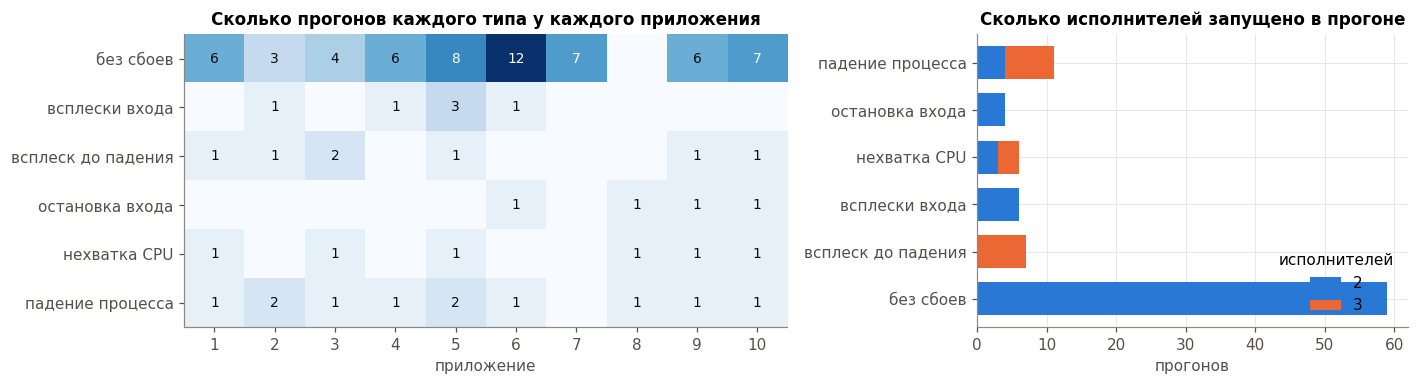

приложение,1,2,3,4,5,6,7,8,9,10
"интервал батча, с",5,5,20,5,5,5,5,10,10,10


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1.4, 1]})
ct = pd.crosstab(inv['приложение'], inv['тип'])
im = axes[0].imshow(ct.T.values, cmap='Blues', aspect='auto'); axes[0].grid(False)
for (i, j), v in np.ndenumerate(ct.T.values):
    if v: axes[0].text(j, i, v, ha='center', va='center', fontsize=9, color='white' if v > 6 else '#0b0b0b')
axes[0].set_xticks(range(len(ct.index))); axes[0].set_xticklabels(ct.index); axes[0].set_xlabel('приложение')
axes[0].set_yticks(range(len(ct.columns))); axes[0].set_yticklabels([TYPES[t] for t in ct.columns])
axes[0].set_title('Сколько прогонов каждого типа у каждого приложения')
ex = pd.crosstab(inv['описание'], inv['исполнителей (обычно)'])
ex.plot.barh(stacked=True, ax=axes[1], color=[C[0], C[1]], width=0.7)
axes[1].set_title('Сколько исполнителей запущено в прогоне'); axes[1].set_xlabel('прогонов'); axes[1].set_ylabel('')
axes[1].legend(title='исполнителей', loc='lower right')
plt.tight_layout(); plt.show()
display(inv.groupby('приложение')['интервал батча, с'].first().to_frame().T)

## 2. Какие признаки мы считаем

### 2.1. Обозначения

**Теория очередей** вот такие прекрасные обозначения я узнала пока читала статью:

| Обозначение | Что значит | Единицы |
|---|---|---|
| $\lambda$ | входящий поток: сколько событий приходит в секунду | событий/с |
| $\mu$ | скорость одного обработчика: сколько событий в секунду он обрабатывает | событий/с |
| $c$ | число обработчиков (у нас — исполнителей) | штук |
| $c \cdot \mu$ | максимальная скорость обработки всей системы | событий/с |
| $\rho$ | загрузка: какая доля возможностей системы занята | доля (0,8 = 80%) |
| $L$ | длина очереди | событий или батчей |
| $W$ | время ожидания в очереди | с |

**Spark и данные Exathlon:**

| Обозначение | Что значит | Из какой колонки |
|---|---|---|
| $t$ | номер секунды (одна строка таблицы) | `t` |
| $\Delta X_t = X_t - X_{t-1}$ | прирост счётчика $X$ за одну секунду | любой счётчик |
| $R_t$ | всего событий **принято** к секунде $t$ | `drv_totalReceivedRecords` |
| $P_t$ | всего событий **обработано** к секунде $t$ | `drv_totalProcessedRecords` |
| $Q_t$ | батчей в очереди | `drv_waitingBatches` |
| $T^{\text{proc}}_t$ | время обработки последнего батча | `drv_lastCompletedBatch_processingDelay` |
| $T^{\text{wait}}_t$ | время ожидания последнего батча в очереди | `drv_lastCompletedBatch_schedulingDelay` |
| $S_t$ | момент создания последнего батча | `drv_lastReceivedBatch_submissionTime` |
| $\tau$ | интервал батча: как часто Spark собирает пачку | вычисляется из $S_t$ |
| $i = 1, \dots, 5$ | номер места (слота) исполнителя | префикс `1_`…`5_` |
| $U^{(i)}_t$ | время работы исполнителя $i$ (счётчик) | `i_executor_runTime_count` |
| $C^{(i)}_t$ | время процессора исполнителя $i$ (счётчик) | `i_executor_cpuTime_count` |
| $G^{(i)}_t$ | время сборки мусора исполнителя $i$ (счётчик) | `i_executor_jvmGCTime_count` |
| $H^{(i)}_t$ | занятая память исполнителя $i$ | `i_jvm_heap_used_value` |
| $k = 5, \dots, 8$ | номер машины (узла) | префикс `node5_`…`node8_` |
| $I^{(k)}_t$ | доля простоя процессора машины $k$, % × 10 | `nodeK_CPU_ALL_Idle%` |

### 2.2. Супер мега важная формула вот такая

**В теории очередей:**

$$\rho = \frac{\lambda}{c \cdot \mu}$$

Загрузка — это отношение того, сколько работы приходит, к тому, сколько система может сделать.

**Условие устойчивости:**

$$\rho < 1 \;\Rightarrow\; \text{система успевает}, \qquad \rho > 1 \;\Rightarrow\; \text{очередь растёт без остановки}$$


**В Spark** ρ можно измерить напрямую, без знания $\mu$ и $c$:

$$\rho_t = \frac{T^{\text{proc}}_t}{\tau}$$

Загрузка = время обработки батча / интервал батча. Батч собирается 5 секунд, а обрабатывается 4 — значит, $\rho = 0{,}8$. Обрабатывается 7 секунд — $\rho = 1{,}4$, и следующий батч встаёт в очередь


### 2.3. Закон Литтла: связь очереди и ожидания, еще одна супер важная формула из статьи

$$L = \lambda \cdot W$$

Средняя длина очереди равна потоку, умноженному на среднее время ожидания. Если приходит 1 000 событий в секунду и каждое ждёт 5 секунд, в очереди в среднем 5 000 событий.

**Зачем нам:** при том же потоке рост времени ожидания $T^{\text{wait}}$ означает рост очереди. Поэтому задержка в очереди — второй измеритель очереди, наравне с $Q_t$.

### 2.4. Как считается каждый признак

**От счётчиков к величинам «в секунду».** Большинство колонок — накопительные счётчики: они только растут с начала прогона. Полезен их **прирост за секунду**:

$$\Delta X_t = X_t - X_{t-1}$$

*Пример:* в секунду 1 000 счётчик принятых событий был 1 000 000, в секунду 1 001 стал 1 050 000. Значит, $\Delta R_t = 50\,000$ событий в секунду.

**Сглаживание.** Spark обновляет счётчики пачками, раз в интервал батча, поэтому посекундные приросты скачут: то 0, то большое число. Короче взяла **скользящее среднее за 10 секунд**:

$$\overline{X}_t = \frac{1}{10} \sum_{j=0}^{9} X_{t-j}$$

**Формулы признаков:**

| Признак | Формула | Что значит |
|---|---|---|
| `in_rate` | $\lambda_t = \overline{\Delta R}_t$ | событий в секунду **на входе**  |
| `out_rate` | $\overline{\Delta P}_t$ | событий в секунду **обработано** |
| `lag_records` | $R_t - P_t$ | событий принято, но ещё не обработано (backlog в событиях) |
| `queue` | $Q_t$ | батчей в очереди (backlog в батчах) |
| `sched_delay_s` | $T^{\text{wait}}_t / 1000$ | сколько батч ждал в очереди, с (в данных мс) |
| `proc_delay_s` | $T^{\text{proc}}_t / 1000$ | сколько батч обрабатывался, с |
| `interval_s` | $\tau = \text{медиана}(\Delta S_t) / 1000$ | интервал батча: 5, 10 или 20 с |
| `rho` | $\rho_t = T^{\text{proc}}_t / \tau$ | **загрузка** |
| `n_exec` | $c_t = $ число слотов $i$, где $U^{(i)}_t$ есть | сколько исполнителей работает |
| `exec_cpu_cores` | $\overline{\sum_i \Delta C^{(i)}_t} / 10^9$ | сколько ядер процессора заняли исполнители (в данных нс) |
| `exec_run_s` | $\overline{\sum_i \Delta U^{(i)}_t} / 1000$ | сколько секунд работы задач за секунду (в данных мс) |
| `cpu_share` | `exec_cpu_cores` / `exec_run_s` | доля времени задач, проведённая на процессоре |
| `exec_gc_s` | $\overline{\sum_i \Delta G^{(i)}_t} / 1000$ | сколько секунд в секунду уходит на сборку мусора |
| `exec_heap_gb` | $\sum_i H^{(i)}_t / 1024$ | память всех исполнителей, ГБ (в данных МБ) |
| `node_cpu_max` | $\max_k \left(100 - I^{(k)}_t / 10\right)$ | загрузка процессора **самой занятой** машины, % |

**Пояснения к некоторым формулам:**

- **Интервал батча $\tau$.** Spark создаёт батчи строго по расписанию, поэтому разница между временем создания соседних батчей $\Delta S_t$ и есть интервал. Берём медиану, чтобы случайные сбои не исказили значение.
- **Ядра процессора.** Если за одну секунду исполнитель накопил 0,5 секунды процессорного времени, он в среднем занимал **половину ядра**. Если два исполнителя накопили по 1 секунде, вместе они заняли 2 ядра.
- **Доля времени на процессоре.** Если задачи работали $U = 10$ с, а на процессоре провели $C = 3$ с, то $\text{cpu\_share} = 0{,}3$: 70% времени задачи **ждали** (процессор, диск или сеть). Когда процессор отнимают соседи, эта доля падает. Так можно отличить «много работы» от «не дают работать». Считаем её, только если задачи вообще работали (больше 0,05 с в секунду).
### 2.5. Связь признаков с моделью очереди

| Модель очереди | Признак в Exathlon |
|---|---|
| входящий поток $\lambda$ | `in_rate` |
| скорость обработки $c \cdot \mu$ | `out_rate` (когда есть очередь) |
| число обработчиков $c$ | `n_exec` |
| загрузка $\rho$ | `rho` |
| очередь $L$ | `queue`, `lag_records` |
| ожидание $W$ | `sched_delay_s` |


Пример ниже: один прогон без сбоев, первые 30 минут.

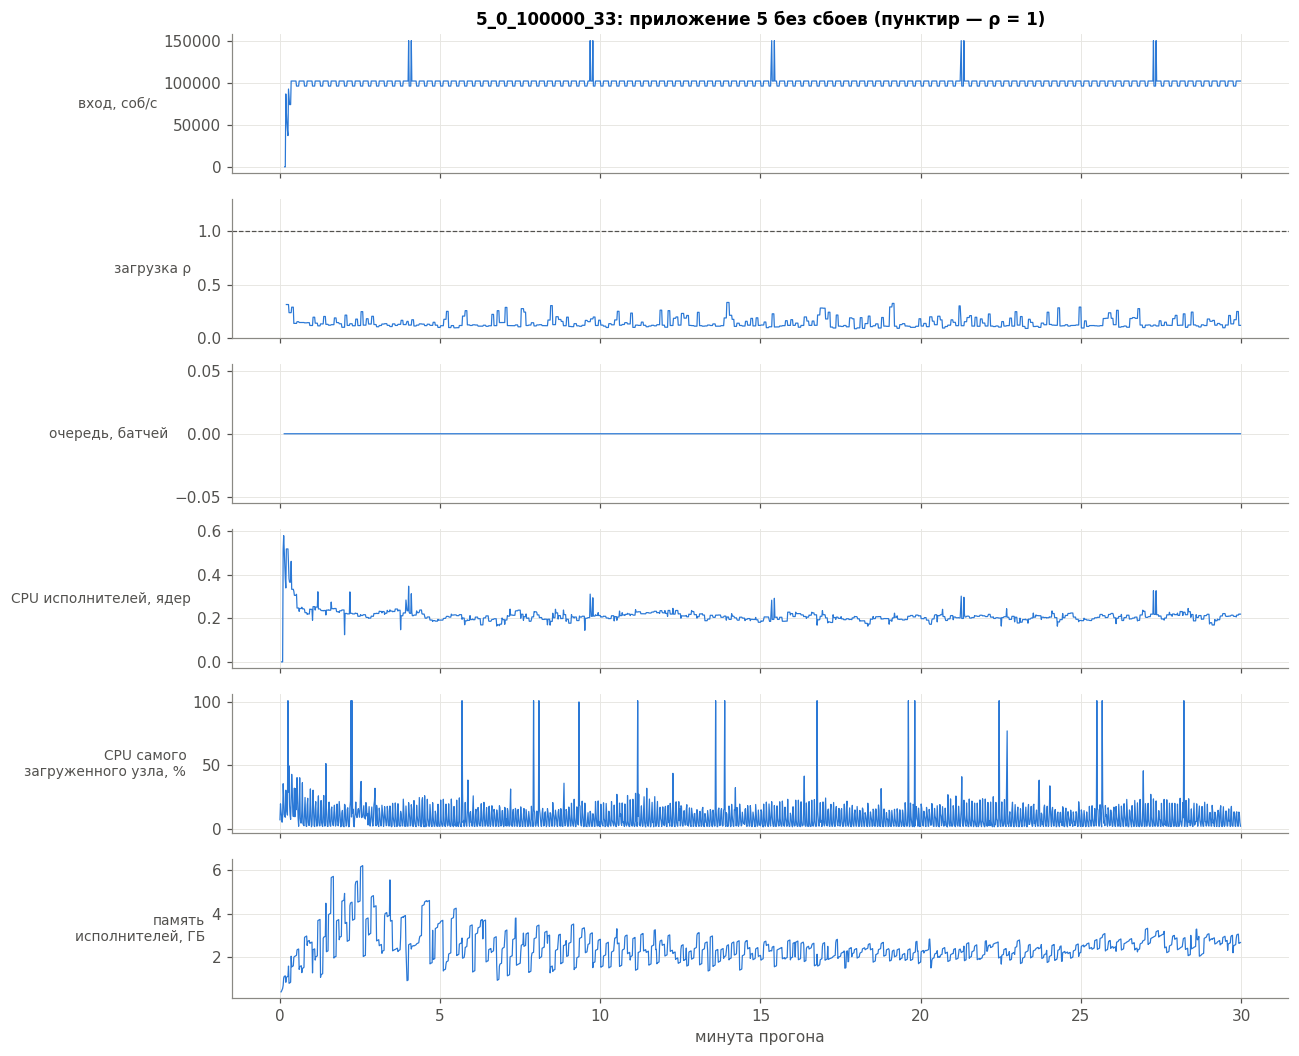

In [8]:
def panel(f, cols, titles, t0=None, t1=None, label=True, title=None, xunit='min'):
    """Несколько метрик одного прогона друг под другом; красным — размеченные аномалии."""
    w = f if t0 is None else f[(f.sec >= t0 * 60) & (f.sec < t1 * 60)]
    x = w.sec / 60
    fig, axes = plt.subplots(len(cols), 1, figsize=(12, 1.55 * len(cols) + 0.4), sharex=True)
    for ax, c, tt in zip(axes, cols, titles):
        ax.plot(x, w[c], lw=0.8, color=C[0])
        if c == 'rho': ax.axhline(1, color='#52514e', ls='--', lw=0.8); ax.set_ylim(0, min(3, max(1.3, w[c].quantile(.995) * 1.1)))
        if label:
            an = (w.label != 'normal').values
            if an.any():
                ax.fill_between(x, 0, 1, where=an, transform=ax.get_xaxis_transform(), color=ANOM, alpha=0.15, lw=0)
        ax.set_ylabel(tt, rotation=0, ha='right', va='center', fontsize=9)
    axes[-1].set_xlabel('минута прогона')
    if title: axes[0].set_title(title)
    plt.tight_layout(); plt.show()

COLS = ['in_rate', 'rho', 'queue', 'exec_cpu_cores', 'node_cpu_max', 'exec_heap_gb']
NAMES = ['вход, соб/с', 'загрузка ρ', 'очередь, батчей', 'CPU исполнителей, ядер', 'CPU самого\nзагруженного узла, %', 'память\nисполнителей, ГБ']
panel(F['5_0_100000_33'], COLS, NAMES, 0, 30, title='5_0_100000_33: приложение 5 без сбоев (пунктир — ρ = 1)')

## 3. Нормальная работа: как приложения ведут себя без сбоев


**Что тут хочу сделать**. Чтобы найти «ненормальное», сначала надо знать, как выглядит «нормальное», baseline вообщем

Берём только прогоны без сбоев (тип 0, 59 прогонов, ~400 часов) и для каждого приложения считаем:
- **медиану**;
- **99-й процентиль (p99)** — так видны редкие высокие значения.

**Почему важно отдельно смотреть на CPU.** Стандартный автоскейлер Kubernetes (HPA)  чаще всего масштабирует по загрузке процессора. Его формула из документации Kubernetes (не судите строка, я это в интернетике прочитала):

> нужное число реплик = текущее число × (текущее значение метрики / целевое значение), с округлением вверх

In [9]:
U = inv[inv['тип'] == 0]
rows = []
for app, g in U.groupby('приложение'):
    ff = pd.concat([F[n].iloc[180:] for n in g['прогон']])
    rows.append({'приложение': app, 'прогонов': len(g), 'часов': round(g['часов'].sum()),
                 'вход, тыс. соб/с (медиана)': round(ff.in_rate.median() / 1e3), 'вход, тыс. соб/с (макс. по прогонам)': round(g['прогон'].map(lambda n: F[n].in_rate.median()).max() / 1e3),
                 'ρ медиана': round(ff.rho.median(), 2), 'ρ 99%': round(ff.rho.quantile(.99), 2),
                 'доля секунд с очередью ≥ 2, %': round((ff.queue >= 2).mean() * 100, 2),
                 'CPU исполнителей, ядер': round(ff.exec_cpu_cores.median(), 2), 'CPU узла макс., %': round(ff.node_cpu_max.median(), 1),
                 'память исполнителей, ГБ': round(ff.exec_heap_gb.median(), 1)})
base = pd.DataFrame(rows).set_index('приложение'); base

,прогонов,часов,"вход, тыс. соб/с (медиана)","вход, тыс. соб/с (макс. по прогонам)",ρ медиана,ρ 99%,"доля секунд с очередью ≥ 2, %","CPU исполнителей, ядер","CPU узла макс., %","память исполнителей, ГБ"
приложение,,,,,,,,,,
1,6,12,510,1020,0.17,0.39,0.00,0.44,17.4,9.6
2,3,19,1152,1224,0.63,1.07,0.42,0.77,9.3,13.7
3,4,32,48,288,0.07,0.30,0.00,0.25,9.1,8.8
4,6,58,102,1020,0.12,0.41,0.17,0.09,6.8,3.4
5,8,37,102,102,0.12,0.30,0.03,0.20,10.4,6.2
6,12,84,102,1224,0.14,0.77,0.17,0.14,7.5,6.4
7,7,35,102,102,0.25,0.43,0.02,0.54,9.7,6.8
9,6,76,144,576,0.12,0.43,0.31,0.23,8.2,6.9
10,7,50,54,576,0.06,0.32,0.04,0.09,11.1,37.1


**Что видно:**
- **В нормальном режиме система сильно недогружена:** медианная ρ 0,06–0,25 у всех приложений, кроме приложения 2. Очередь ≥ 2 почти не встречается (до 0,4% времени).
- **Приложение 2 работает близко к пределу:** вход ~1,15 млн событий в секунду, ρ медиана 0,63, а в 1% случаев больше 1.
- **Процессоры почти свободны:** исполнители занимают 0,1–0,8 ядра, а на каждом узле 32 ядра; самый загруженный узел — 7–17%.


## 4. При какой нагрузке система перестаёт успевать

### 4.1. Загрузка ρ в зависимости от входного потока

**В Теории.** Если обработка одного события занимает примерно одно и то же время, то время обработки батча пропорционально числу событий в нём. Значит, ρ должна расти **прямо пропорционально потоку**:

ρ ≈ a + b × вход,

где b — сколько загрузки добавляет каждый миллион событий в секунду, а a — постоянные накладные расходы. Там, где прямая пересекает ρ = 1, находится **предел**: максимальный поток, который она выдерживает при данном числе исполнителей.

**Что делаю.** Для каждого обработанного батча знаем его размер и время обработки:
- размер / интервал = входной поток, событий в секунду;
- время обработки / интервал = ρ.

Берём батчи **в нормальном режиме и во время всплесков входа** (это просто повышенная нагрузка). Батчи во время сбоев (нехватка CPU, падения, остановка входа) исключаем: там система работает не в штатном режиме. Берём только конфигурацию с 2 исполнителями: её больше всего.

**Как читать график.** Точки — медианы по 20 группам батчей (от самых маленьких потоков к самым большим), линия — прямая по ним, пунктир — ρ = 1 (предел).

Батчей всего: 365,119


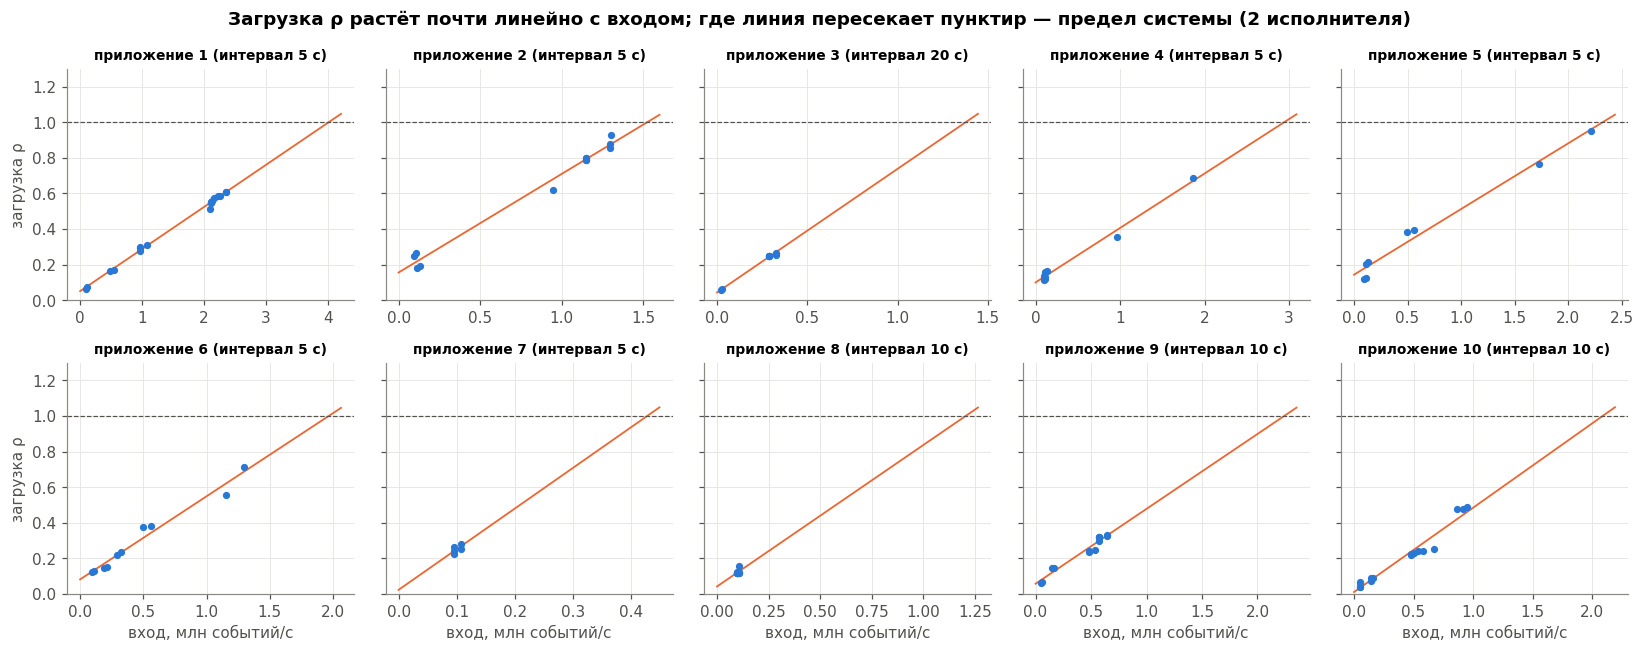

,"интервал, с",батчей,"наблюдаемый вход, млн соб/с",ρ на 1 млн соб/с,"вход при ρ = 0,8, млн соб/с","предел (ρ = 1), млн соб/с",данные близко к пределу
приложение,,,,,,,
1,5,15525,0.01–2.36,0.29,3.17,4.01,"нет, экстраполяция"
2,5,23594,0.10–1.79,0.71,1.16,1.52,да
3,20,5808,0.02–0.51,0.74,1.09,1.38,"нет, экстраполяция"
4,5,56331,0.10–2.06,0.41,2.29,2.94,"нет, экстраполяция"
5,5,56185,0.10–2.49,0.51,1.78,2.32,да
6,5,78488,0.01–2.40,0.55,1.54,1.96,да
7,5,24752,0.05–0.11,2.30,0.34,0.43,"нет, экстраполяция"
8,10,4353,0.10–1.23,0.84,0.95,1.20,да
9,10,31597,0.05–0.67,0.48,1.76,2.24,"нет, экстраполяция"


In [10]:
B = []
for n in TRACE_PARTS:
    d = pd.read_parquet(f'{SLIM}/{n}.parquet', columns=['drv_totalCompletedBatches', 'drv_totalProcessedRecords']).replace(-1, np.nan)
    f = F[n]
    k = d['drv_totalCompletedBatches'].diff() == 1                         # ровно один батч завершился в эту секунду
    b = pd.DataFrame({'records': d['drv_totalProcessedRecords'].diff(), 'proc_s': f.proc_delay_s, 'interval': f.interval_s,
                      'n_exec': f.n_exec, 'queue': f.queue, 'label': f.label, 'sec': f.sec})[k]
    b = b[(b.records > 0) & b.proc_s.notna() & (b.sec > 180)]
    b['rate'] = b.records / b.interval; b['rho'] = b.proc_s / b.interval
    b['trace'] = n; b['app'] = int(n.split('_')[0])
    B.append(b)
B = pd.concat(B, ignore_index=True)
print(f'Батчей всего: {len(B):,}')
L = B[B.label.isin(['normal', 'bursty_input']) & (B.n_exec == 2)]

fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharey=True)
cap = []
for ax, app in zip(axes.flat, range(1, 11)):
    g = L[L.app == app]
    q = pd.qcut(g.rate, 20, duplicates='drop')
    t = g.groupby(q, observed=True).agg(rate=('rate', 'median'), rho=('rho', 'median'))
    k, b0 = np.polyfit(t.rate / 1e6, t.rho, 1)
    xs = np.linspace(0, max((1 - b0) / k * 1.05, t.rate.max() / 1e6), 50)
    ax.plot(xs, b0 + k * xs, color=C[1], lw=1.2)
    ax.scatter(t.rate / 1e6, t.rho, s=14, color=C[0], zorder=3)
    ax.axhline(1, color='#52514e', ls='--', lw=0.8)
    ax.set_title(f'приложение {app} (интервал {int(g.interval.iloc[0])} с)', fontsize=9)
    ax.set_ylim(0, 1.3)
    cap.append({'приложение': app, 'интервал, с': int(g.interval.iloc[0]), 'батчей': len(g),
                'наблюдаемый вход, млн соб/с': f'{g.rate.quantile(.01)/1e6:.2f}–{g.rate.quantile(.99)/1e6:.2f}',
                'ρ на 1 млн соб/с': round(b0 + k, 2), 'вход при ρ = 0,8, млн соб/с': round((0.8 - b0) / k, 2),
                'предел (ρ = 1), млн соб/с': round((1 - b0) / k, 2), 'данные близко к пределу': 'да' if (g.rate.quantile(.99) / 1e6) >= 0.8 * (1 - b0) / k else 'нет, экстраполяция'})
for ax in axes[1]: ax.set_xlabel('вход, млн событий/с')
for ax in axes[:, 0]: ax.set_ylabel('загрузка ρ')
plt.suptitle('Загрузка ρ растёт почти линейно с входом; где линия пересекает пунктир — предел системы (2 исполнителя)', fontweight='bold')
plt.tight_layout(); plt.show()
capacity = pd.DataFrame(cap).set_index('приложение'); capacity

**Что видно:**
- **Загрузка ρ растёт почти линейно со входом:** ρ ≈ a + b × вход. Вот эта формула из терии получается: ρ = λ / (c·μ), то есть время обработки пропорционально числу событий
- **Предел (ρ = 1) у приложений очень разный:** от ~0,4 млн событий в секунду до ~4 млн. Значит, порог автоскейлера нельзя задать одним числом RPS для всех сервисов: его нужно считать для каждого
- **Надёжность оценки разная.** У приложений 2, 5, 6, 8 данные доходят близко к пределу, там оценка надёжная. У остальных пришлось продолжать прямую далеко за пределы данных (столбец «данные близко к пределу» = «нет»): это ориентир, а не измерение
- **Как использовать:** пока не знаю, нл столбец «вход при ρ = 0,8» как будто разумный порог для автоскейлера с запасом 20%. Например, приложению 2 при входе больше ~1,2 млн событий в секунду пора добавлять ресурсы.

### 4.2. Проверка: правда ли очередь растёт, когда ρ > 1

**В теории: почему около 0,9 уже не очень** В простейшей модели очереди (M/M/1: события приходят случайно, обслуживание занимает случайное время, обработчик один) средняя длина очереди равна **L = ρ / (1 − ρ)**:

| ρ | 0,5 | 0,8 | 0,9 | 0,95 | 0,99 |
|---|---|---|---|---|---|
| средняя очередь | 1 | 4 | 9 | 19 | 99 |

Рядом с 1 очередь растёт интесивно: запаса почти нет, и любое случайное колебание создаёт очередь, которую некому разобрать. В Spark батчи приходят по расписанию, а не случайно, поэтому числа там другие, но форма та же: чем ближе к 1, тем печальнее.

Документация Spark описывает признак отставания так:

> Если время обработки батча **стабильно** больше интервала и/или задержка в очереди **продолжает расти**, значит, система не успевает обрабатывать батчи так же быстро, как они создаются, и отстаёт.

И уточняет, что короткие скачки допустимы:


>
> Кратковременный рост задержки из-за временного роста потока допустим, если задержка потом возвращается к низкому значению.

Поэтому смотрим не на отдельные батчи, а на **среднюю ρ за 10 минут**.

**Что делаю.** Беру все прогоны и каждую минуту смотрим две вещи:
- **среднюю загрузку ρ за последние 10 минут;**
- **вырастет ли очередь** до 2 и до 10 батчей в **следующие** 10 минут.

Потом группируем минуты по уровню ρ и считаем, в какой доле случаев очередь выросла.

,минут,очередь_2,очередь_10
группа,,,
"< 0,3",27507,3.9,1.6
"0,3–0,5",3921,5.7,2.2
"0,5–0,7",3554,4.0,1.4
"0,7–0,8",1144,14.1,4.2
"0,8–0,9",1065,8.1,5.0
"0,9–1,0",256,27.7,10.5
"1,0–1,2",242,94.2,87.6
"1,2–1,5",94,81.9,81.9
"> 1,5",135,89.6,85.9


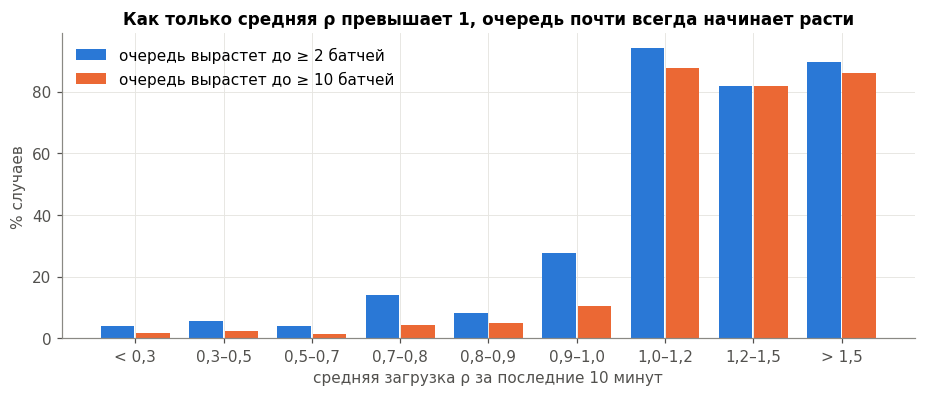

In [11]:
out = []
for n, f in F.items():
    r10 = f.rho.rolling(600, min_periods=300).mean()
    fut = f.queue[::-1].rolling(600, min_periods=1).max()[::-1].shift(-1)       # максимум очереди в следующие 10 мин
    out.append(pd.DataFrame({'rho10': r10, 'future_q': fut}).iloc[600::60])
O = pd.concat(out).dropna()
edges = [0, .3, .5, .7, .8, .9, 1.0, 1.2, 1.5, 100]
names = ['< 0,3', '0,3–0,5', '0,5–0,7', '0,7–0,8', '0,8–0,9', '0,9–1,0', '1,0–1,2', '1,2–1,5', '> 1,5']
O['группа'] = pd.cut(O.rho10, edges, labels=names)
st = O.groupby('группа', observed=True).agg(минут=('future_q', 'size'),
        очередь_2=('future_q', lambda x: (x >= 2).mean() * 100), очередь_10=('future_q', lambda x: (x >= 10).mean() * 100)).round(1)
display(st)
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(st)); w = 0.38
ax.bar(x - w / 2 - 0.01, st['очередь_2'], w, color=C[0], label='очередь вырастет до ≥ 2 батчей')
ax.bar(x + w / 2 + 0.01, st['очередь_10'], w, color=C[1], label='очередь вырастет до ≥ 10 батчей')
ax.set_xticks(x); ax.set_xticklabels(st.index); ax.set_xlabel('средняя загрузка ρ за последние 10 минут')
ax.set_ylabel('% случаев'); ax.set_title('Как только средняя ρ превышает 1, очередь почти всегда начинает расти')
ax.legend(loc='upper left'); plt.show()

**Ура, условие устойчивости ρ < 1 подтверждается на реальных данных.**
- Пока средняя ρ за 10 минут **ниже 0,9**, очередь вырастает до 10 батчей лишь в 1–5% случаев.
- В зоне **0,9–1,0** риск уже заметный: в 28% случаев очередь дорастает до 2, в 10% — до 10.
- Как только средняя ρ **превышает 1**, очередь вырастает до 10 батчей в **82–88%** случаев.

**Почему очередь иногда растёт и при низкой ρ?** Потому что у очереди есть и другие причины: падение исполнителя, кратковременный «застой» обработки, остановка и догоняющий всплеск входа. Их разбираю в разделах 5–7.

**Вывод для автоскейлера:** рабочая граница наверное **ρ ≈ 0,9**. Выше неё система ещё справляется, но запаса уже нет.

## 5. CPU и память вместе с потоком и очередью

**Что делаю.** Средние числа не показывают, как признаки меняются вместе во время проблемы. Поэтому разбираем шесть конкретных ситуаций из **разных приложений и разных типов прогонов**.

**Как читать графики.** На каждом 8 полосок сверху вниз:

| Полоска | Что показывает | Теоретически |
|---|---|---|
| вход | событий в секунду | λ |
| загрузка ρ | время обработки / интервал | ρ |
| очередь | батчей ждёт | backlog |
| CPU исполнителей | сколько ядер заняли исполнители | сколько реально считают |
| доля времени на CPU | сколько времени задачи считали, а не ждали | падает, если отнимают процессор |
| CPU узла | загрузка самой занятой машины | соседи и общий фон |
| память исполнителей | ГБ | растёт с объёмом данных |
| число исполнителей | сколько работает | c |

Красная заливка — размеченная аномалия. Время — в минутах от начала аномалии (отрицательное значит до неё).

**На что смотреть.** В формуле ρ = λ / (c·μ) ρ может вырасти по трём разным причинам:
- вырос **поток λ** (всплеск нагрузки);
- упала **скорость μ** (процессор отняли соседи, медленная деградация);
- уменьшилось **число исполнителей c** (падение исполнителя).

В каждом случае ниже стоит определить, какая из трёх величин изменилась.

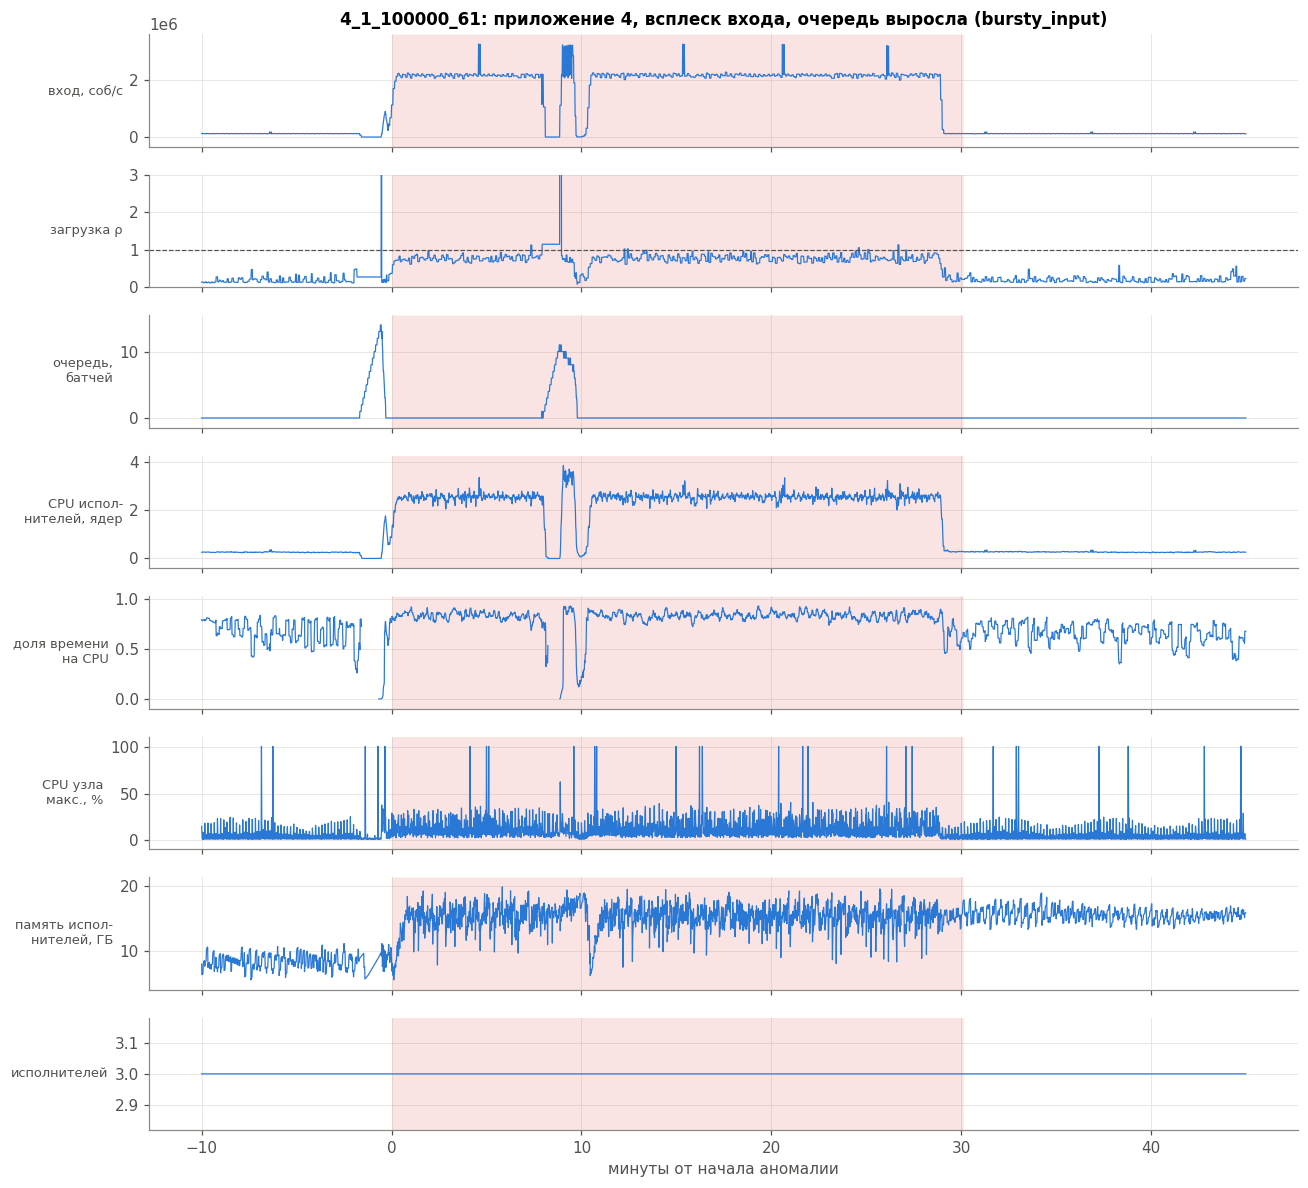

In [12]:
COLS8 = ['in_rate', 'rho', 'queue', 'exec_cpu_cores', 'cpu_share', 'node_cpu_max', 'exec_heap_gb', 'n_exec']
NAMES8 = ['вход, соб/с', 'загрузка ρ', 'очередь,\nбатчей', 'CPU испол-\nнителей, ядер', 'доля времени\nна CPU', 'CPU узла\nмакс., %', 'память испол-\nнителей, ГБ', 'исполнителей']

def event_window(trace, k, before=10, after=40, title=''):
    """Окно вокруг k-го события разметки прогона."""
    f = F[trace]; ev = gt[gt.trace_name == trace].reset_index(drop=True).iloc[k]
    rel = (f.t - ev.root_cause_start) / 60
    w = f[(rel >= -before) & (rel < after)].copy(); w['rel'] = rel[(rel >= -before) & (rel < after)]
    fig, axes = plt.subplots(len(COLS8), 1, figsize=(12, 1.3 * len(COLS8) + 0.5), sharex=True)
    an = (w.label != 'normal').values
    for ax, c, nm in zip(axes, COLS8, NAMES8):
        ax.plot(w.rel, w[c], lw=0.8, color=C[0])
        ax.fill_between(w.rel, 0, 1, where=an, transform=ax.get_xaxis_transform(), color=ANOM, alpha=0.15, lw=0)
        if c == 'rho': ax.axhline(1, color='#52514e', ls='--', lw=0.8); ax.set_ylim(0, 3)
        ax.set_ylabel(nm, rotation=0, ha='right', va='center', fontsize=8.5)
    axes[0].set_title(f'{trace}: {title} ({ev.anomaly_type})')
    axes[-1].set_xlabel('минуты от начала аномалии'); plt.tight_layout(); plt.show()
    return w

w1 = event_window('4_1_100000_61', 0, 10, 45, 'приложение 4, всплеск входа, очередь выросла')

**Всплеск входа в приложении 4 (3 исполнителя):**
- На минуте 0 вход вырос **в ~17 раз** (с 0,12 до ~2,1 млн событий в секунду).
- **ρ мгновенно выросла** с ~0,15 до ~0,8, но **осталась ниже 1**.
- **CPU исполнителей** вырос с 0,3 до ~2,5 ядер, доля времени на CPU — с ~0,6 до ~0,85: задачи стали вычислительными. **Память** выросла с ~8 до ~16 ГБ.
- **CPU узлов почти не изменился** (10–20%): машины большие, 32 ядра.
- **Очередь выросла дважды, но ненадолго:** до ~14 батчей прямо перед всплеском и до ~11 на 8–9 минуте. Оба раза вход и CPU падают до нуля, а один батч обрабатывается очень долго (пик ρ). Это **«застой»**: обработка на минуту замирает. Потом очередь рассасывается за 1–2 минуты, потому что ρ < 1.

**Что значит:** скачок очереди ≠ нехватка мощности. Если ρ остальных батчей ниже 1, очередь рассосётся сама, и добавлять исполнителей не нужно.

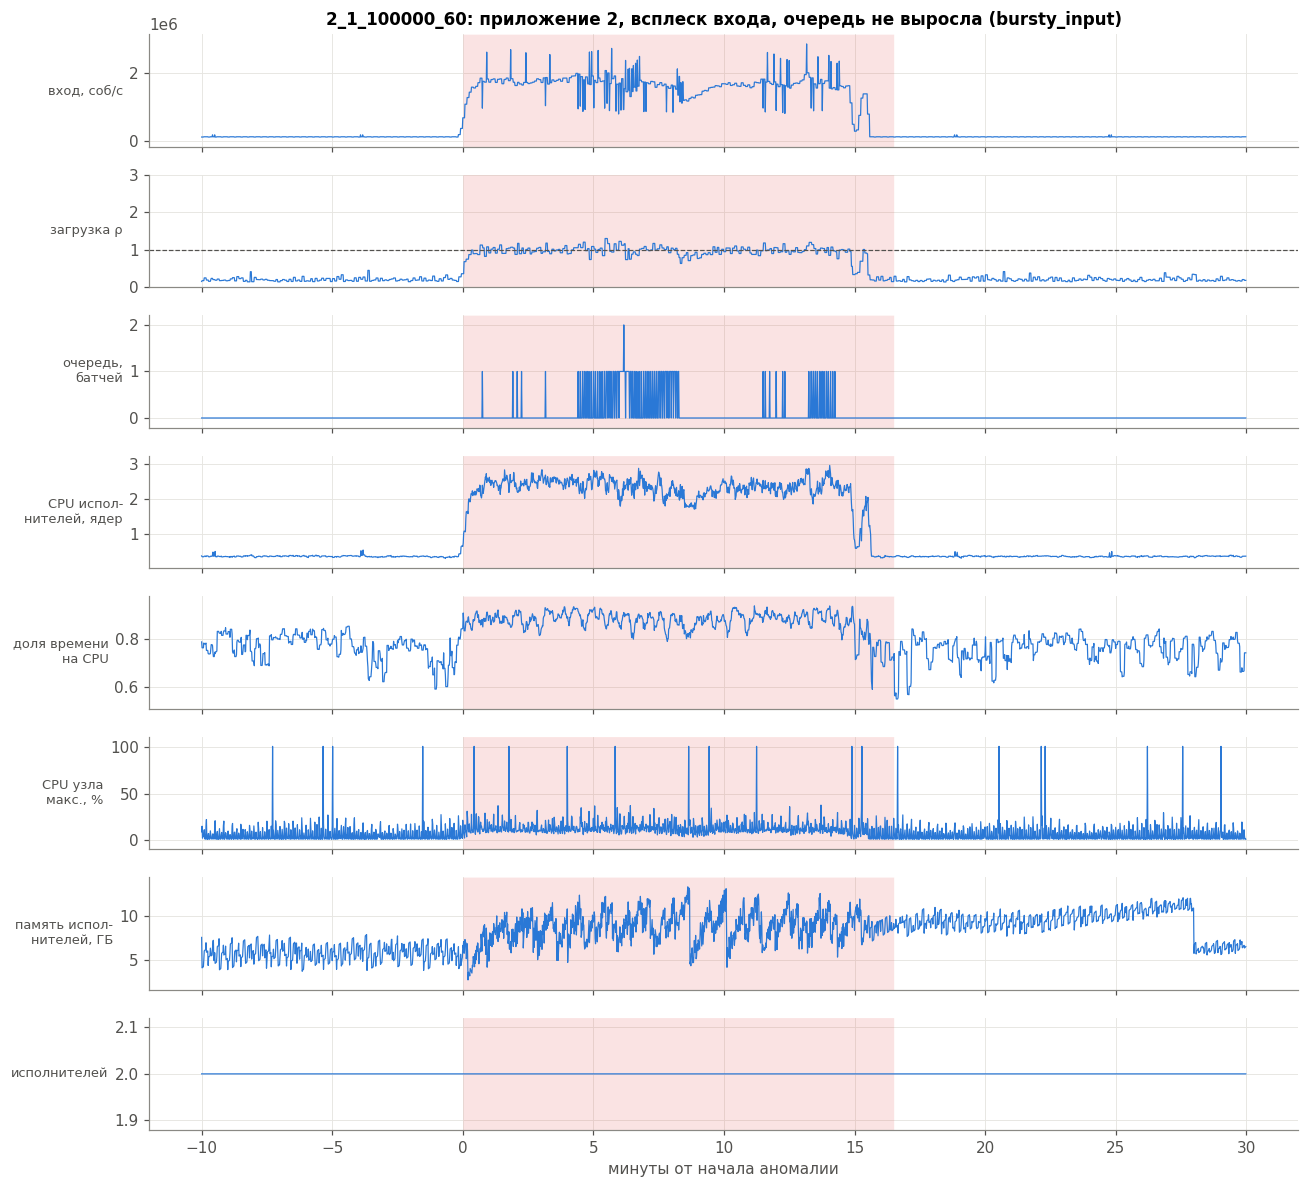

In [13]:
w2 = event_window('2_1_100000_60', 0, 10, 30, 'приложение 2, всплеск входа, очередь не выросла')

**Всплеск входа в приложении 2, очередь не выросла (2 исполнителя):**
- Вход вырос **в ~14 раз**, до ~1,7–1,8 млн событий в секунду. Это около предела приложения 2 (оценка в разделе 4.1 — ~1,5 млн).
- **ρ держится около 0,95–1,0** все 15 минут: система работает ровно на пределе.
- **Очередь мерцает между 0 и 1** (один раз 2), но не растёт: обработка успевает впритык.
- CPU исполнителей вырос с ~0,4 до ~2,5 ядер, CPU узлов по-прежнему ниже 20%.

**Что значит:** при ρ ≈ 1 очередь не взрывается сразу, но **запаса нет**: любой лишний всплеск или медленный батч — и она начнёт расти. Сравните с разделом 4.2: при средней ρ 0,9–1,0 риск уже заметный.

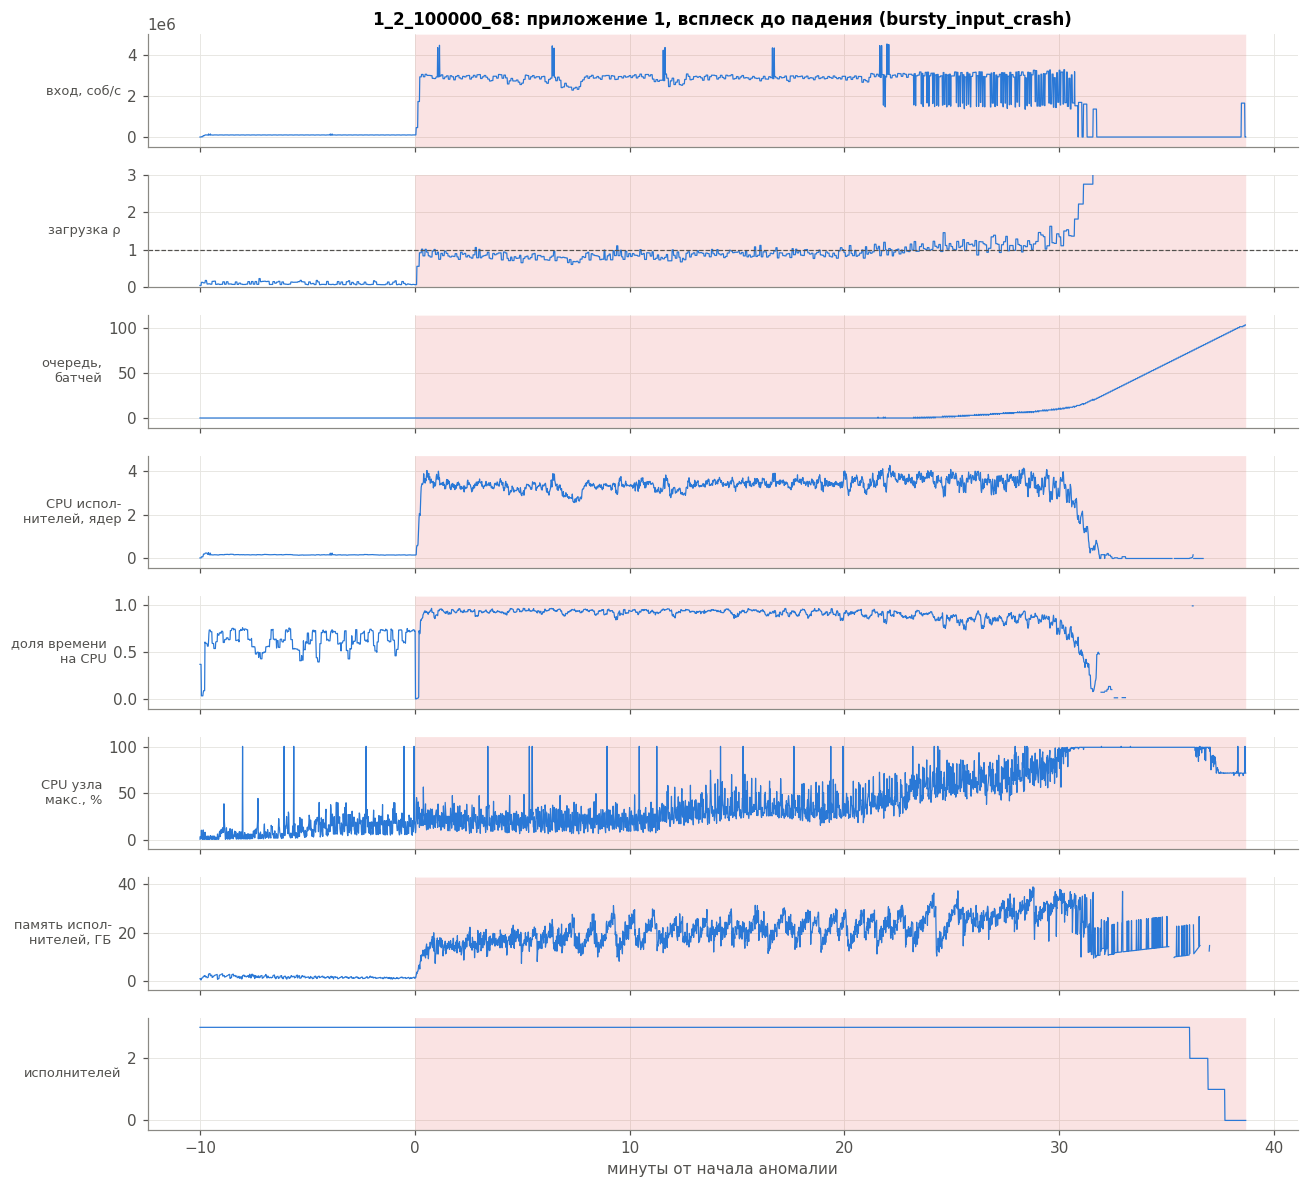

In [14]:
w3 = event_window('1_2_100000_68', 0, 10, 40, 'приложение 1, всплеск до падения')

**Всплеск до падения в приложении 1 (3 исполнителя):**
- Вход вырос **в ~29 раз**, до ~2,9 млн событий в секунду.
- **ρ сразу поднялась до ~0,85–0,95, то есть ниже 1**, и первые ~20 минут система справляется.
- Дальше идёт **постепенная деградация**:
  - с ~20-й минуты **ρ медленно ползёт выше 1**;
  - **CPU самого загруженного узла** растёт с ~20% до 100%;
  - **память исполнителей** растёт с ~15 до ~35 ГБ;
  - с ~23-й минуты **начинает расти очередь**, потом линейно до 100+ батчей.
- На ~31-й минуте обработка останавливается (CPU исполнителей падает до нуля), на 36–38-й минутах **исполнители пропадают один за другим** и система падает.

**Что значит:** здесь были **ранние признаки за несколько минут до роста очереди**: медленный рост ρ к 1, рост CPU узла и памяти. Предиктивный автоскейлер должен бы уловить такую штуку.

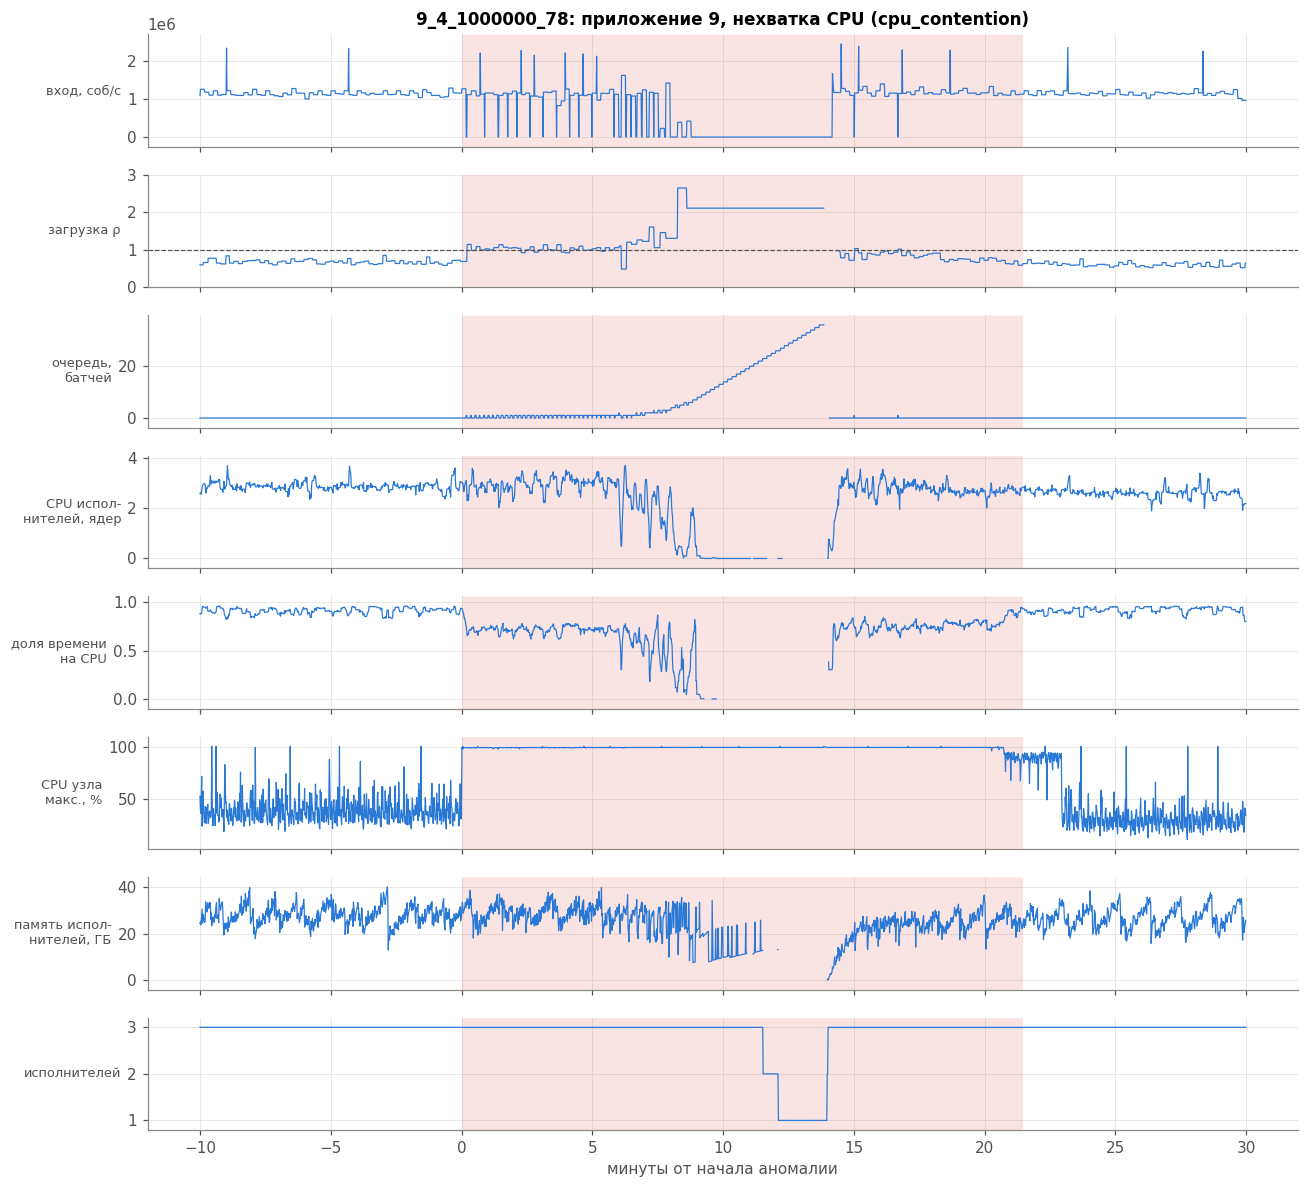

In [15]:
w4 = event_window('9_4_1000000_78', 3, 10, 30, 'приложение 9, нехватка CPU')

**Нехватка CPU в приложении 9 (3 исполнителя):**
- **Вход не изменился** (~1,1 млн событий в секунду).
- На минуте 0 **CPU самого загруженного узла подскочил до 100%**: на узле запустили «прожорливую» программу.
- **Доля времени на CPU упала** с ~0,9 до ~0,7: задачи исполнителей ждут процессор.
- **ρ выросла** с ~0,7 до ~1,0, и с ~6-й минуты **начала расти очередь**.
- Около 8-й минуты обработка встала, на 11–14-й минутах исполнители пропали, а на 14-й минуте всё перезапустилось: очередь обнулилась, вернулись 3 исполнителя (похоже на перезапуск приложения).

**Что значит:** очередь растёт **не из-за нагрузки**, а из-за того, что у исполнителей отняли процессор. Добавлять исполнителей на тот же перегруженный узел бессмысленно: нужно дать им процессор, например запустить на свободном узле.

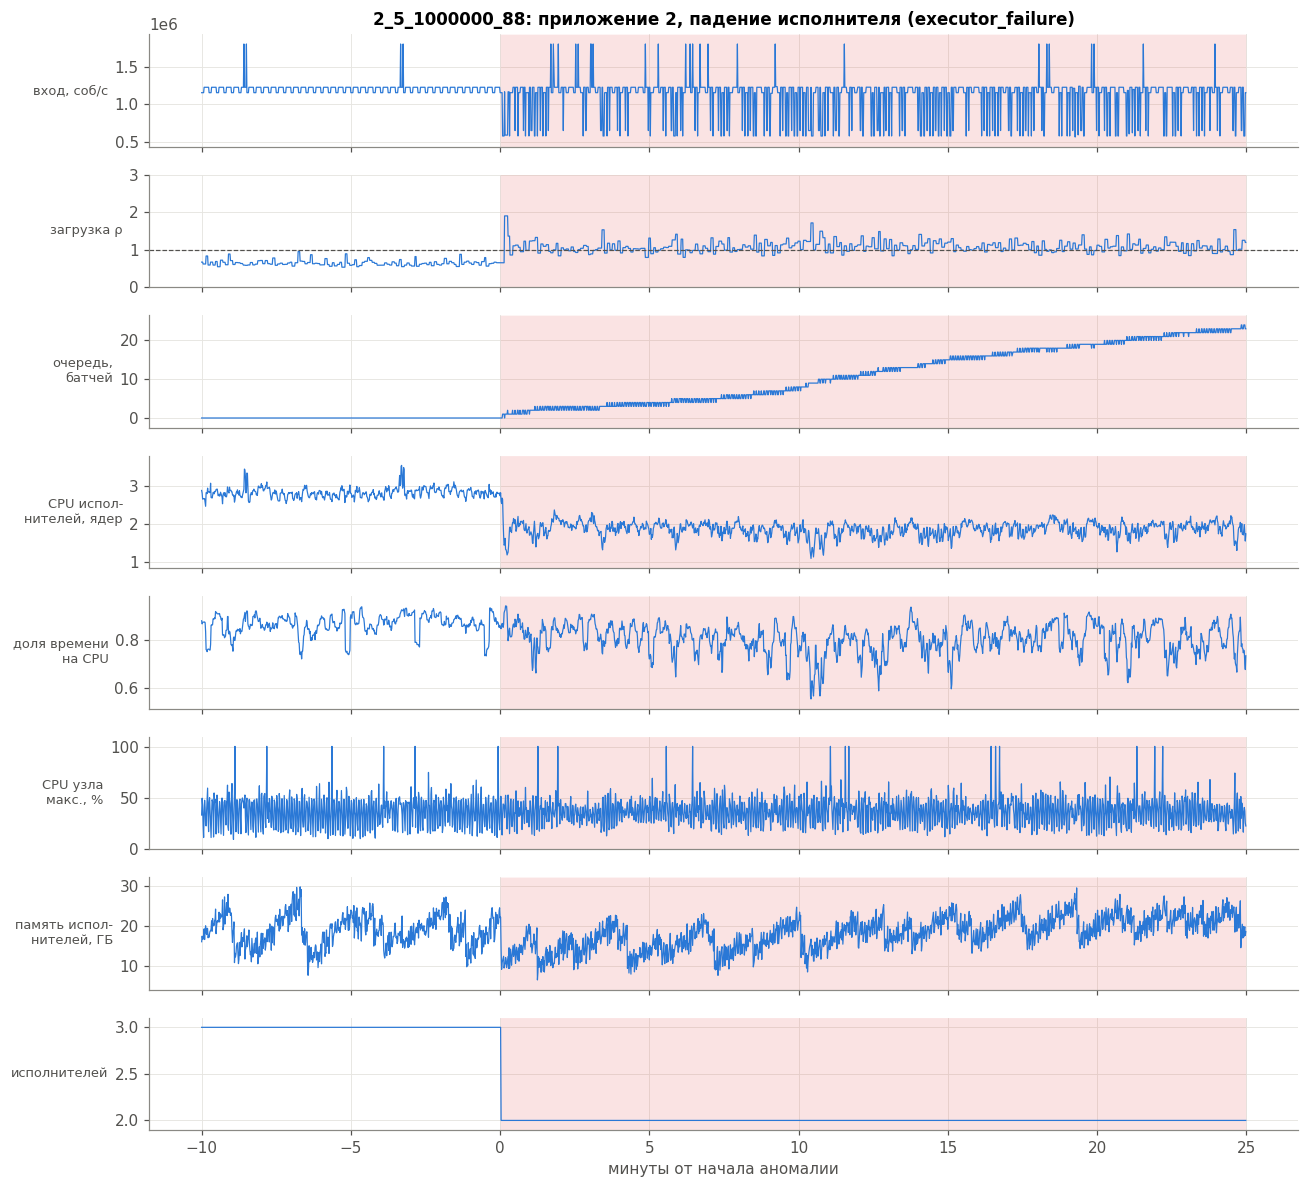

In [16]:
w5 = event_window('2_5_1000000_88', 0, 10, 25, 'приложение 2, падение исполнителя')

**Падение исполнителя в приложении 2 (3 исполнителя):**
- **Вход не изменился** (~1,2 млн событий в секунду).
- На минуте 0 **исполнителей стало 2 вместо 3**. CPU исполнителей упал с ~2,8 до ~1,9 ядра: мощность снизилась на треть.
- **ρ выросла** с ~0,65 до ~1,05, то есть **выше 1**.
- **Очередь растёт линейно**, ~1 батч в минуту, до 23 батчей за 25 минут. **Замена исполнителю так и не появилась.**

**Что значит:** классический случай для автоскейлера. Мощность упала ниже нагрузки, и сразу видны два сигнала: **исполнителей стало меньше** и **ρ > 1**. Надо бы сразу поднять замену.

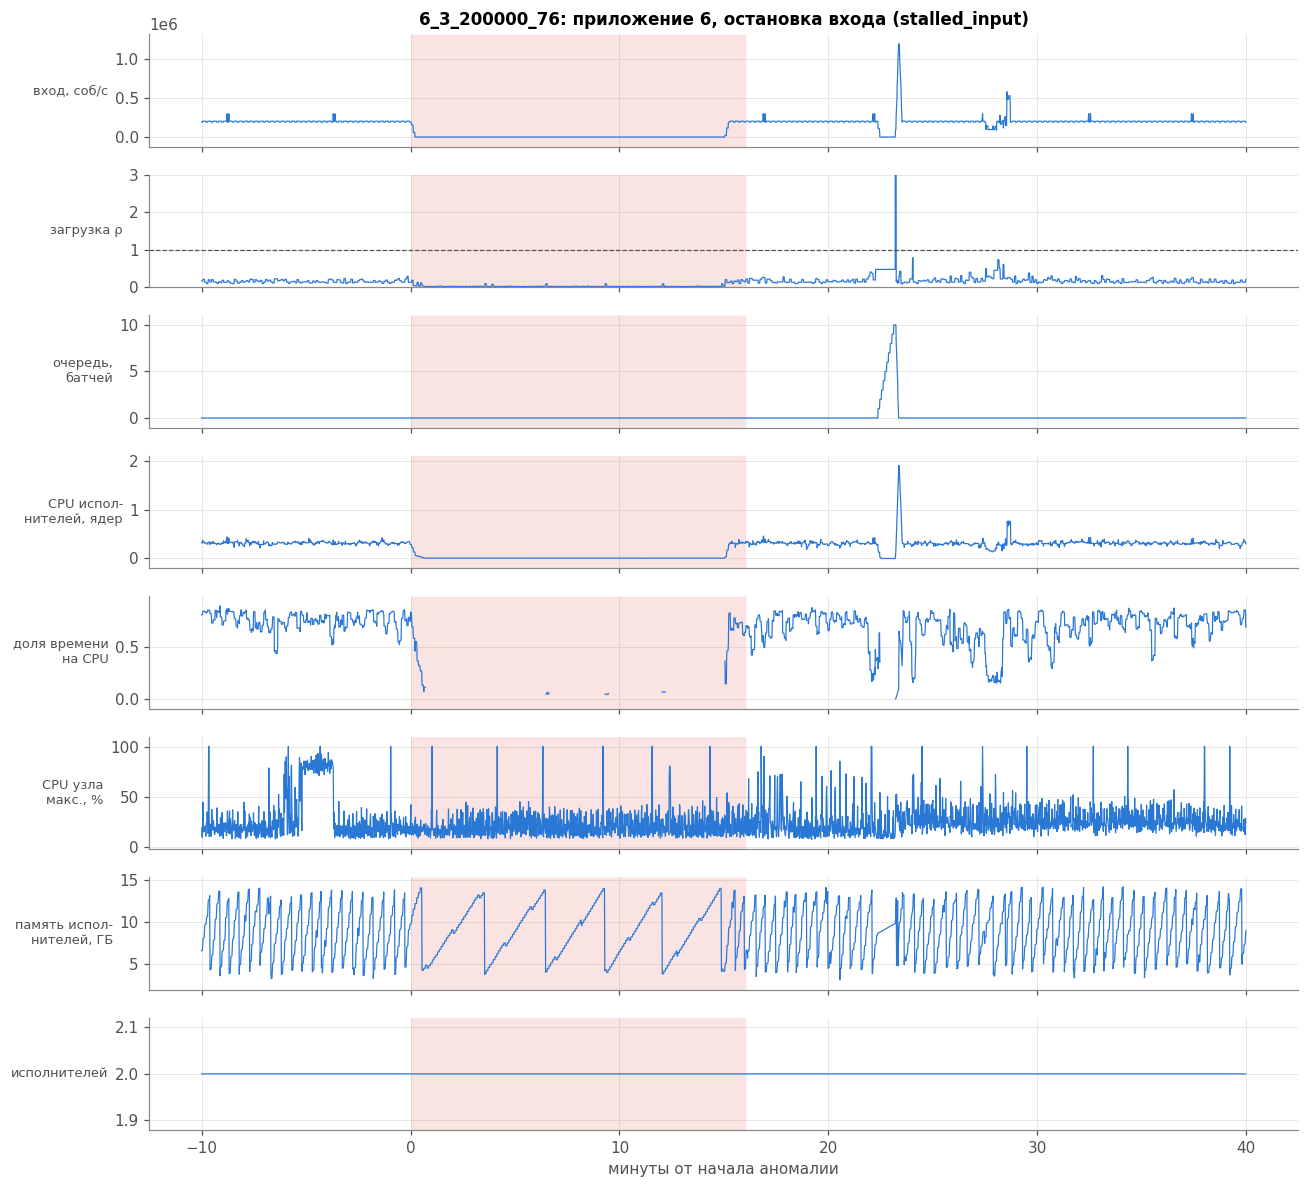

In [17]:
w6 = event_window('6_3_200000_76', 1, 10, 40, 'приложение 6, остановка входа')

**Остановка входа в приложении 6 (2 исполнителя):**
- На минуте 0 **вход упал до нуля** на ~15 минут. Вместе с ним упали ρ и CPU, память стала медленнее «пилить».
- **Очередь пустая**: обрабатывать нечего.
- Через ~6 минут после восстановления был **короткий всплеск входа** (до ~1,2 млн/с, вероятно, «догоняющие» данные) и один долгий батч → очередь на минуту выросла до 10 и сразу рассосалась.

**Что значит:** низкий вход не всегда повод уменьшать число исполнителей. Если поток пропал внезапно,значит что то неладное, а после восстановления может прийти догоняющий всплеск.

### 5.1. С чем связана загрузка ρ в разных режимах

**Коэффициент ранговой корреляции(вот это вспомнили)** — число от −1 до +1, которое показывает, насколько две величины **меняются вместе**:
- **+1** — когда одна растёт, другая всегда растёт;
- **0** — связи нет;
- **−1** — когда одна растёт, другая всегда падает.

В отличие от обычной корреляции Пирсона, смотрит не на сами значения, а на их **порядок** (ранги). Поэтому он не боится выбросов и нелинейных зависимостей. Для метрик с резкими скачками это удобно.

**Что делаю.** По всем прогонам считаем поминутные медианы признаков и корреляцию между ρ и остальными признаками **отдельно** для нормальной работы, всплесков входа и нехватки CPU. Если связи различаются, значит, по сопутствующим признакам можно понять **причину** роста ρ.

In [18]:
M = []
for n, f in F.items():
    m = f.assign(minute=f.sec // 60).groupby('minute').agg({**{c: 'median' for c in ['in_rate', 'rho', 'exec_cpu_cores', 'cpu_share', 'node_cpu_max', 'exec_heap_gb', 'exec_gc_s', 'queue']}, 'label': 'first'})
    m['trace'] = n; M.append(m.iloc[3:])
M = pd.concat(M)
SIGN = {'in_rate': 'вход', 'exec_cpu_cores': 'CPU исполнителей', 'cpu_share': 'доля времени на CPU', 'node_cpu_max': 'CPU узла макс.', 'exec_heap_gb': 'память исполнителей', 'exec_gc_s': 'сборка мусора'}
corr = pd.DataFrame({lab: M[M.label == lab][['rho'] + list(SIGN)].corr(method='spearman')['rho'].drop('rho')
                     for lab in ['normal', 'bursty_input', 'cpu_contention']}).rename(index=SIGN)
corr.columns = ['нормальная работа', 'всплески входа', 'нехватка CPU']
display(corr.round(2))

,нормальная работа,всплески входа,нехватка CPU
вход,0.85,0.58,0.11
CPU исполнителей,0.85,0.56,0.35
доля времени на CPU,0.07,0.50,-0.61
CPU узла макс.,0.34,0.55,0.45
память исполнителей,0.40,0.28,0.22
сборка мусора,0.66,0.02,0.53


**Что видно:**
- **В нормальной работе** ρ сильно связана с входом (0,85) и CPU исполнителей (0,85): чем больше событий, тем дольше обработка. Связь со сборкой мусора тоже заметная (0,66).
- **При нехватке CPU** связь со входом почти исчезает (0,11). Зато ρ растёт, когда **падает доля времени на CPU** (−0,61) и **растёт CPU узла** (0,45): задачи ждут процессор.
- **При всплесках входа** картина промежуточная.

**Вывод:** одна и та же метрика (рост ρ и очереди) может иметь разные причины, и по сопутствующим признакам их можно различить.

## 6. Какие признаки появляются до роста очереди

**Что делаю.** Стандартные автоскейлеры вроде как реагируют на то, что **уже произошло**, то есть по длине очереди:

> Целевое значение суммарного отставания (сумма по всем партициям), при котором запускается масштабирование. По умолчанию 10.

Если очередь — **запаздывающий** сигнал, такой автоскейлер всегда опаздывает. Ищем признаки, которые появляются **раньше**.

### 6.1. Нагрузка растёт сразу,а очередь позже

**Выравнием по событию.** Все события «прикладываем» друг к другу так, чтобы их начало совпало (минута 0), и смотрим типичное поведение до и после. Так случайные особенности отдельных событий усредняются, а общая закономерность остаётся.

Отдельно рассматриваем всплески входа (29 событий) и всплески до падения (7 событий). Линия — медиана по событиям, заливка — разброс от 25% до 75% (половина событий внутри неё).

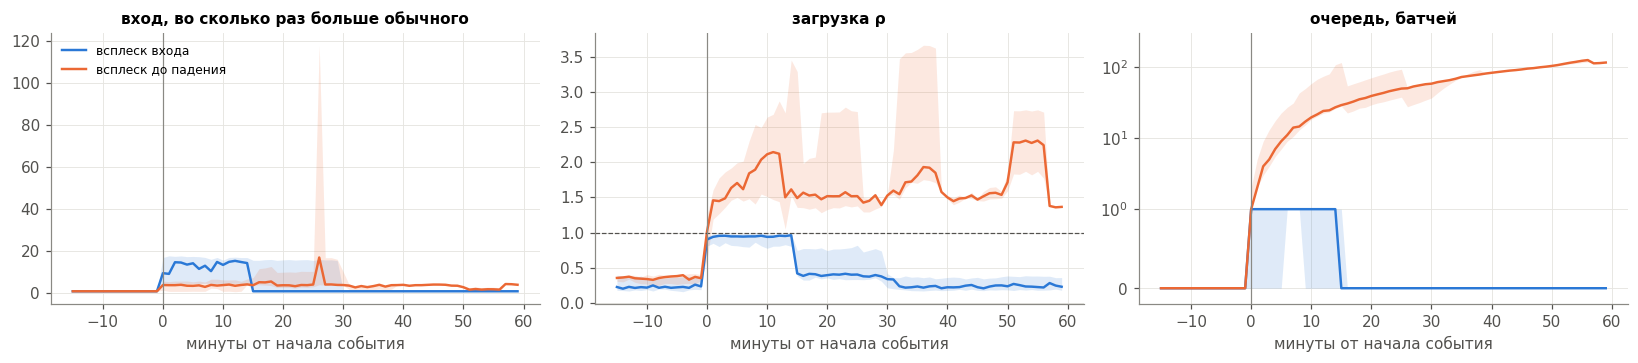

In [19]:
SIG6 = ['in_rate', 'rho', 'sched_delay_s', 'exec_cpu_cores', 'cpu_share', 'node_cpu_max', 'exec_heap_gb', 'exec_gc_s', 'n_exec']
A = []
for k, r in enumerate(gt.itertuples()):
    f = F[r.trace_name]
    rel = (f.t - r.root_cause_start) / 60
    w = f[(rel >= -15) & (rel < 60)].copy(); w['rel'] = np.floor(rel[(rel >= -15) & (rel < 60)]).astype(int)
    m = w.groupby('rel')[SIG6].median()
    m['queue'] = w.groupby('rel').queue.max()                 # максимум очереди за минуту
    m['rho_peak'] = w.groupby('rel').rho.max()                # самый долгий батч за минуту
    base = m[m.index < 0].median()
    m['in_ratio'] = m.in_rate / max(base.in_rate, 1)
    m['event'] = k; m['type'] = r.anomaly_type; m['trace'] = r.trace_name
    A.append(m.reset_index())
A = pd.concat(A, ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (c, nm) in zip(axes, [('in_ratio', 'вход, во сколько раз больше обычного'), ('rho', 'загрузка ρ'), ('queue', 'очередь, батчей')]):
    for ty, col, lab in [('bursty_input', C[0], 'всплеск входа'), ('bursty_input_crash', C[1], 'всплеск до падения')]:
        g = A[A.type == ty].groupby('rel')[c]
        ax.plot(g.median().index, g.median(), color=col, lw=1.6, label=lab)
        ax.fill_between(g.median().index, g.quantile(.25), g.quantile(.75), color=col, alpha=0.15, lw=0)
    if c == 'rho': ax.axhline(1, color='#52514e', ls='--', lw=0.8)
    if c == 'queue': ax.set_yscale('symlog', linthresh=1); ax.set_ylim(-0.2, 300)
    ax.axvline(0, color='#8a8984', lw=0.8); ax.set_title(nm, fontsize=10); ax.set_xlabel('минуты от начала события')
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

**Что видно:**
- **Вход и загрузка ρ меняются сразу, на минуте 0.** При всплесках входа ρ подскакивает с ~0,25 до ~0,95, при всплесках до падения — с ~0,35 до 1,5–2.
- **Очередь реагирует по-разному:**
  - при обычных всплесках медиана очереди остаётся ~1 батч: система держится на пределе;
  - при всплесках до падения очередь начинает расти уже через 1–2 минуты и к концу часа доходит до ~100 батчей.

**Что значит:** ρ — **мгновенный** сигнал, а очередь — **запаздывающий**. Если смотреть только на очередь, автоскейлер всегда будет опаздывать.

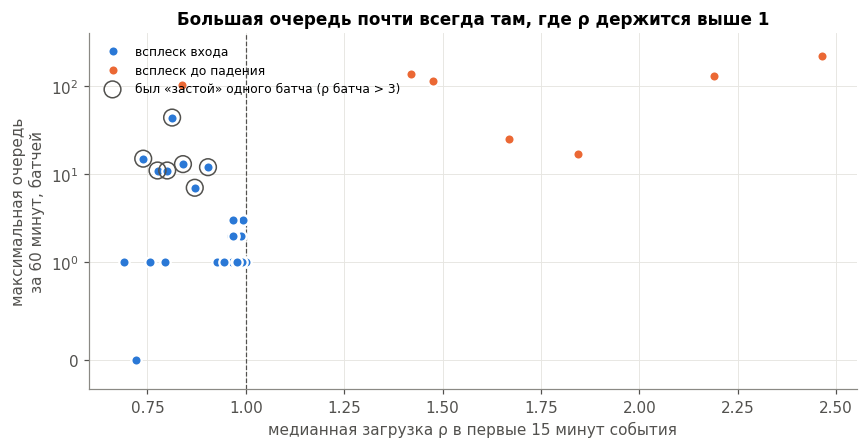

,событий,ρ_медиана,очередь_медиана,очередь_макс
type,,,,
bursty_input,29,0.96,1.0,44.0
bursty_input_crash,7,1.67,115.0,220.0


In [20]:
pts = []
for e, g in A[A.type.isin(['bursty_input', 'bursty_input_crash'])].groupby('event'):
    p = g[(g.rel >= 0) & (g.rel < 15)]
    pts.append({'event': e, 'type': g.type.iloc[0], 'trace': g.trace.iloc[0], 'rho15': p.rho.median(),
                'queue60': g[g.rel >= 0].queue.max(), 'stall': (g[(g.rel >= -2)].rho_peak > 3).any()})
P = pd.DataFrame(pts)
fig, ax = plt.subplots(figsize=(9, 4.2))
for ty, col, lab in [('bursty_input', C[0], 'всплеск входа'), ('bursty_input_crash', C[1], 'всплеск до падения')]:
    q = P[P.type == ty]
    ax.scatter(q.rho15, q.queue60, s=46, color=col, label=lab, edgecolor='white', linewidth=1.5, zorder=3)
st = P[(P.type == 'bursty_input') & P.stall & (P.queue60 >= 5)]
ax.scatter(st.rho15, st.queue60, s=120, facecolor='none', edgecolor='#52514e', linewidth=1, zorder=4, label='был «застой» одного батча (ρ батча > 3)')
ax.axvline(1, color='#52514e', ls='--', lw=0.8)
ax.set_yscale('symlog', linthresh=1); ax.set_ylim(-0.3, 400); ax.set_xlabel('медианная загрузка ρ в первые 15 минут события')
ax.set_ylabel('максимальная очередь\nза 60 минут, батчей'); ax.set_title('Большая очередь почти всегда там, где ρ держится выше 1')
ax.legend(loc='upper left', fontsize=8); plt.show()
display(P.groupby('type').agg(событий=('event', 'size'), ρ_медиана=('rho15', 'median'), очередь_медиана=('queue60', 'median'),
        очередь_макс=('queue60', 'max')).round(2))

**Каждая точка это одно событие:** по горизонтали медианная ρ в первые 15 минут, по вертикали самая большая очередь за час.

- **Все всплески до падения, кроме одного, — справа от ρ = 1** (ρ 1,4–2,5), с очередью от 15 до 220 батчей.
- **Обычные всплески — слева** (ρ 0,7–1,0): очередь обычно 0–4 батча.
- **Исключения слева с очередью 7–44 батча** (обведены) — это события с **«застоем»**: один батч обрабатывался больше трёх интервалов. Очередь там набегает скачком, а не из-за нехватки мощности, и потом рассасывается.
- **Ещё одно исключение — прогон 1_2** (ρ ≈ 0,84, очередь ~100): ρ перешла через 1 только через ~20 минут после начала (постепенная деградация, раздел 5).

**Ответ на вопрос «при какой нагрузке система перестаёт успевать»:** когда загрузка ρ **устойчиво** выше 1, то есть когда вход превышает предел из таблицы раздела 4.1. В зоне 0,9–1 система работает без запаса.

### 6.2. Сколько минут проходит от первого признака до большой очереди

Берём события любого типа (кроме неразмеченных `unknown`), где **до начала очередь была меньше 2**, а после выросла **до ≥ 10 батчей**. Для каждого находим первую минуту, когда:
- **застой:** хотя бы один батч обрабатывался дольше 3 интервалов;
- **ρ > 0,9** две минуты подряд;
- **ρ > 1** две минуты подряд;
- очередь ≥ 2 и очередь ≥ 10.

In [21]:
def first_minute(g, cond, need=2):
    s = set(g.rel[cond(g)])
    for x in sorted(s):
        if need == 1 or (x + 1) in s: return x
    return np.nan
rows = []
for e, g in A[A.type != 'unknown'].groupby('event'):
    before = g[(g.rel >= -2) & (g.rel < 0)].queue.max()
    post = g[g.rel >= 0].sort_values('rel')
    if before >= 2 or post.queue.max() < 10: continue
    rows.append({'событие': e, 'тип': TNAME.get(g.type.iloc[0], g.type.iloc[0]), 'прогон': g.trace.iloc[0],
                 'застой батча': first_minute(post, lambda x: x.rho_peak > 3, 1),
                 'ρ > 0,9': first_minute(post, lambda x: x.rho > 0.9),
                 'ρ > 1': first_minute(post, lambda x: x.rho > 1),
                 'очередь ≥ 2': first_minute(post, lambda x: x.queue >= 2, 1),
                 'очередь ≥ 10': first_minute(post, lambda x: x.queue >= 10, 1)})
lead = pd.DataFrame(rows).set_index('событие')
display(lead)
for c in ['застой батча', 'ρ > 0,9', 'ρ > 1', 'очередь ≥ 2']:
    dlt = (lead['очередь ≥ 10'] - lead[c]).dropna()
    print(f'{c:13s}: был в {len(dlt):2d} из {len(lead)} событий; раньше «очередь ≥ 10» на {dlt.median():.0f} мин (медиана), разброс {dlt.min():.0f}…{dlt.max():.0f}')

,тип,прогон,застой батча,"ρ > 0,9",ρ > 1,очередь ≥ 2,очередь ≥ 10
событие,,,,,,,
4,всплеск входа,4_1_100000_61,9.0,NaN,NaN,8,9
6,всплеск входа,4_1_100000_61,13.0,9.0,9.0,9,9
7,всплеск входа,4_1_100000_61,6.0,5.0,5.0,5,6
10,всплеск входа,4_1_100000_61,7.0,NaN,NaN,6,7
18,всплеск входа,5_1_100000_63,46.0,0.0,NaN,45,46
29,всплеск до падения,9_2_1000000_66,51.0,0.0,0.0,1,6
30,всплеск до падения,10_2_1000000_67,NaN,0.0,0.0,1,6
31,всплеск до падения,1_2_100000_68,31.0,13.0,23.0,24,29
32,всплеск до падения,2_2_200000_69,12.0,0.0,0.0,0,1


застой батча : был в 14 из 19 событий; раньше «очередь ≥ 10» на -2 мин (медиана), разброс -45…0
ρ > 0,9      : был в 15 из 19 событий; раньше «очередь ≥ 10» на 5 мин (медиана), разброс 0…46
ρ > 1        : был в 14 из 19 событий; раньше «очередь ≥ 10» на 4 мин (медиана), разброс 0…10
очередь ≥ 2  : был в 19 из 19 событий; раньше «очередь ≥ 10» на 2 мин (медиана), разброс 0…21


**Что видно** (19 событий, где очередь выросла с < 2 до ≥ 10 батчей):
- **ρ > 1 две минуты подряд** была в 14 событиях из 19 и появлялась в среднем **за ~4 минуты** до того, как очередь дорастала до 10 батчей (от 0 до 10 минут).
- **ρ > 0,9** была в 15 событиях, **за ~5 минут** (в прогоне 1_2 — за 17 минут: 13-я минута против 30-й).
- **Очередь ≥ 2** — за ~2 минуты. Это тоже ранний сигнал, но короче.
- **«Застой» батча** (батч дольше трёх интервалов) обычно случается в ту же минуту, что и рост очереди, или позже. Это **механизм**, а не ранний признак.

**Для будущего предиктивного автоскейлера:**
1. **Главный ранний сигнал это устойчивая ρ > 0,9.** Она даёт ~5 минут форы по сравнению с порогом по очереди, а при медленной деградации — до 15–20 минут.
2. **Время реакции должно быть меньше этой форы.** Если новый исполнитель запускается за 1–2 минуты, реагировать по ρ успеваем, а по очереди ≥ 10 — уже нет.
3. Признаки нужно сглаживать (две минуты подряд), иначе одиночные долгие батчи дадут ложные срабатывания.

## 7. Почему растёт очередь: у разных причин разный «почерк»

**Идея.** Если причины роста очереди разные, то и сопутствующие признаки должны меняться по-разному. Найдём что то типо признака для каждого типа события.

**Что делаю.** Для каждого события сравниваю первые 15 минут после начала с 15 минутами до него. Для каждого признака считаем, **во сколько раз** он изменился, и берём медиану по событиям одного типа.

**Почему логарифм.** На тепловой карте показан **двоичный логарифм отношения** (log2):

| log2 | Во сколько раз изменилось |
|---|---|
| +3 | выросло в 8 раз |
| +2 | выросло в 4 раза |
| +1 | выросло в 2 раза |
| 0 | не изменилось |
| −1 | упало в 2 раза |
| −4 | упало в 16 раз |

Без логарифма рост в 2 раза выглядел бы как «2», а падение в 2 раза — как «0,5», и на карте они были бы несимметричны. С логарифмом это +1 и −1)

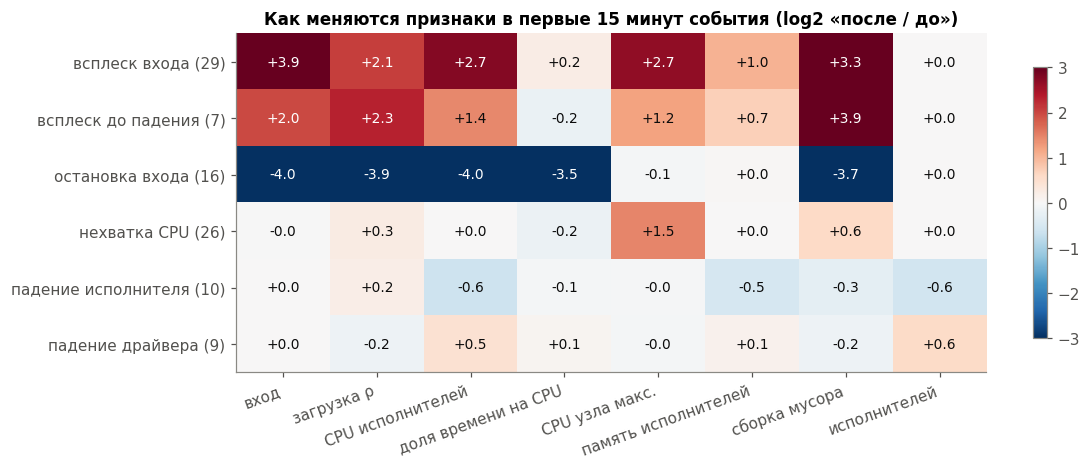

,событий,очередь_выросла_до_2,очередь_макс_медиана
type,,,
всплеск входа,29,48.0,1.0
всплеск до падения,7,100.0,115.0
остановка входа,16,25.0,0.0
нехватка CPU,26,35.0,1.0
падение исполнителя,10,80.0,2.0
падение драйвера,9,22.0,1.0


In [22]:
SIG7 = {'in_rate': 'вход', 'rho': 'загрузка ρ', 'exec_cpu_cores': 'CPU исполнителей', 'cpu_share': 'доля времени на CPU',
        'node_cpu_max': 'CPU узла макс.', 'exec_heap_gb': 'память исполнителей', 'exec_gc_s': 'сборка мусора', 'n_exec': 'исполнителей'}
TNAME = {'bursty_input': 'всплеск входа', 'bursty_input_crash': 'всплеск до падения', 'stalled_input': 'остановка входа',
         'cpu_contention': 'нехватка CPU', 'executor_failure': 'падение исполнителя', 'driver_failure': 'падение драйвера'}
sig = []
for e, g in A[A.type.isin(TNAME)].groupby('event'):
    pre = g[g.rel < 0][list(SIG7)].median(); post = g[(g.rel >= 0) & (g.rel < 15)][list(SIG7)].median()
    r = np.log2((post + 1e-3) / (pre + 1e-3)).clip(-4, 4)
    r['type'] = g.type.iloc[0]; r['queue_max'] = g[g.rel >= 0].queue.max(); sig.append(r)
sig = pd.DataFrame(sig)
H = sig.groupby('type')[list(SIG7)].median().reindex(list(TNAME)).rename(index=TNAME, columns=SIG7)
cnt = sig.groupby('type').size().reindex(list(TNAME))
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(H.values.astype(float), cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto'); ax.grid(False)
for (i, j), v in np.ndenumerate(H.values.astype(float)):
    if not np.isnan(v): ax.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=9, color='white' if abs(v) > 1.8 else '#0b0b0b')
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns, rotation=20, ha='right')
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels([f'{t} ({n})' for t, n in zip(H.index, cnt)])
ax.set_title('Как меняются признаки в первые 15 минут события (log2 «после / до»)'); plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()
qs = sig.groupby('type').agg(событий=('queue_max', 'size'), очередь_выросла_до_2=('queue_max', lambda x: (x >= 2).mean() * 100),
                             очередь_макс_медиана=('queue_max', 'median')).reindex(list(TNAME)).rename(index=TNAME).round(0)
display(qs)

**Как читать:** красное — выросло, синее — упало. +2 = выросло в 4 раза, −4 = упало в 16 раз. В скобках — число событий.

| Тип события | «Почерк» в первые 15 минут | Как часто растёт очередь |
|---|---|---|
| **Всплеск входа** | вход ×15, ρ ×4, CPU исполнителей ×6, CPU узла ×6, сборка мусора ×10; исполнителей столько же | в 28% событий, обычно на 1–2 батча |
| **Всплеск до падения** | вход ×4, но ρ ×5: на событие приходится больше работы; сборка мусора ×15 | всегда, до ~100 батчей |
| **Остановка входа** | всё падает в ~16 раз: вход, ρ, CPU исполнителей, сборка мусора | редко (19%), уже после восстановления входа |
| **Нехватка CPU** | вход не меняется, CPU узла ×3, ρ ×1,2, доля времени на CPU снижается | в 19% событий |
| **Падение исполнителя** | исполнителей меньше (3 → 2), CPU исполнителей и память падают, ρ растёт | в 50% событий |
| **Падение драйвера** | почти ничего не видно: метрики пропадают и приложение перезапускается | не растёт (метрики обнуляются) |

**Получается**

| Что видим | Вероятная причина | Что делать |
|---|---|---|
| вход ↑, ρ ↑, CPU исполнителей ↑, число исполнителей то же | рост нагрузки | **добавить исполнителей**, если ρ держится выше ~0,9 |
| вход тот же, ρ ↑, CPU узла ~100%, доля времени на CPU ↓ | нехватка CPU на узле (мешают соседи) | добавлять на тот же узел бесполезно: **перенести на свободный узел**, предупредить |
| исполнителей стало меньше, CPU исполнителей ↓, ρ ↑ | упал исполнитель | **сразу поднять замену** (сам Spark это делает не всегда, раздел 8) |
| вход резко упал до 0 | проблема у источника | **не уменьшать** число исполнителей сразу, поднять тревогу, ждать догоняющего всплеска |
| одиночный очень долгий батч, очередь скачком, остальные батчи с ρ < 1 | кратковременный «застой» | **не масштабировать**: очередь рассосётся сама |
| ρ медленно ползёт к 1, растут память и CPU узла | постепенная деградация | **масштабировать заранее**, возможно, перезапуск |



## 8. Как реально меняется число исполнителей

**Что делаем** Автоскейлер управляет именно числом исполнителей. Нужно понять, меняется ли оно в данных само, а если меняется, то когда и почему.

**Что говорит документация Spark о сбоях.** Spark различает два вида отказов:

> *Перевод:* **отказ рабочего узла** — любой узел с исполнителями может отказать, и все данные в его памяти будут потеряны. […] **Отказ узла драйвера** — если падает драйвер, теряется всё приложение, а вместе с ним и все исполнители с данными в памяти.

Авторы Exathlon добавляют, что упавший исполнитель «*may have been replaced or stayed down until either the application crash or the end of its recording*» — **мог быть заменён, а мог и не вернуться** до падения приложения или конца записи. Ниже считаем, как часто бывает каждое.

### 8.1. Сколько исполнителей запущено

У каждого прогона 5 «слотов» для исполнителей (колонки `1_…` – `5_…`). Слот считаем активным, если у него есть данные. Короткие пропуски до 60 секунд — это сбои передачи метрик, а не настоящая остановка, их заполняем.

In [ ]:
rows = []
for n, f in F.items():
    nn = f.n_exec.iloc[120:-60]
    rows.append({'прогон': n, 'тип': TYPES[int(n.split('_')[1])], 'обычно': int(nn.median()), 'минимум': int(nn.min()), 'максимум': int(nn.max()),
                 'всех исполнителей не было, % времени': round((nn == 0).mean() * 100, 1), 'слотов задействовано': int(f[[f'slot{i}' for i in EXEC]].max().sum())})
ex = pd.DataFrame(rows)
display(ex.groupby('тип').agg(прогонов=('прогон', 'size'), обычно_2=('обычно', lambda x: (x == 2).sum()), обычно_3=('обычно', lambda x: (x == 3).sum()),
        число_менялось=('прогон', lambda x: (ex.loc[x.index, 'минимум'] != ex.loc[x.index, 'максимум']).sum()),
        задействовано_больше_слотов=('слотов задействовано', lambda x: (x > ex.loc[x.index, 'обычно']).sum())))

,прогонов,обычно_2,обычно_3,число_менялось,задействовано_больше_слотов
тип,,,,,
без сбоев,59,59,0,0,0
всплеск до падения,7,0,7,7,6
всплески входа,6,6,0,1,1
нехватка CPU,6,3,3,3,2
остановка входа,4,4,0,0,0
падение процесса,11,4,7,8,3


### 8.2. Все изменения посреди прогона

Ищем моменты, когда слот исполнителя **пропадает** или **появляется** не в первые 2 минуты и не в последнюю минуту прогона, и сопоставляем их с разметкой.

In [23]:
ev_rows = []
for n, f in F.items():
    dur = f.sec.iloc[-1]
    for i in EXEC:
        a = f[f'slot{i}'].values; da = np.diff(a)
        for k in np.flatnonzero(da != 0):
            sec = f.sec.iloc[k + 1]
            if 120 < sec < dur - 60:
                ev_rows.append({'прогон': n, 'тип прогона': TYPES[int(n.split('_')[1])], 'минута': round(sec / 60, 1), 'слот': i,
                                'что': 'появился' if da[k] > 0 else 'пропал', 't': f.t.iloc[k + 1]})
EV = pd.DataFrame(ev_rows)
def nearest_gt(r):
    g = gt[gt.trace_name == r['прогон']]
    if g.empty: return ''
    dt = (r['t'] - g.root_cause_start).abs(); j = dt.idxmin()
    return f"{g.loc[j, 'anomaly_type']} ({(r['t'] - g.loc[j, 'root_cause_start']) / 60:+.1f} мин)"
EV['ближайшее событие разметки'] = EV.apply(nearest_gt, axis=1)
print('Прогонов с изменениями посреди работы:', EV['прогон'].nunique(), 'из', len(F))
display(EV.drop(columns='t').sort_values(['тип прогона', 'прогон', 'минута']).reset_index(drop=True))

Прогонов с изменениями посреди работы: 19 из 93


,прогон,тип прогона,минута,слот,что,ближайшее событие разметки
0,10_2_1000000_67,всплеск до падения,165.2,3,пропал,bursty_input_crash (+81.3 мин)
1,10_2_1000000_67,всплеск до падения,168.0,2,пропал,bursty_input_crash (+84.0 мин)
2,10_2_1000000_67,всплеск до падения,168.1,4,появился,bursty_input_crash (+84.1 мин)
3,1_2_100000_68,всплеск до падения,46.5,2,пропал,bursty_input_crash (+36.1 мин)
4,1_2_100000_68,всплеск до падения,47.3,1,пропал,bursty_input_crash (+36.9 мин)
...,...,...,...,...,...,...
73,5_5_1000000_91,падение процесса,484.2,3,появился,driver_failure (+0.1 мин)
74,8_5_1000000_83,падение процесса,33.6,2,пропал,executor_failure (+0.0 мин)
75,8_5_1000000_83,падение процесса,50.6,2,появился,driver_failure (+0.2 мин)
76,9_5_1000000_84,падение процесса,10.2,3,пропал,executor_failure (+0.0 мин)


**Что видно:** изменения посреди работы есть только в **19 из 93** прогонов, и **ни в одном прогоне без сбоев**. Все они связаны со сбоями:

1. **Прогоны без сбоев (59):** всё время работают 2 исполнителя. **Автоматического масштабирования в этих экспериментах нет:** Spark не добавлял и не убирал исполнителей по нагрузке.
2. **Падение исполнителя (10 событий):** исполнитель пропадает точно в момент сбоя. Но **замена появилась сразу только в 2 случаях из 10** (прогоны 1_5 и 5_5_91, в течение секунд). В остальных 8:
   - в 5 случаях число исполнителей вернулось только после **падения драйвера**, когда перезапустилось всё приложение: через 17–167 минут;
   - в 3 случаях замена **так и не появилась** до конца прогона (27–53 минуты).

   Получется, всё это время система работала с меньшей мощностью.
3. **Всплеск до падения (7 прогонов):** в конце исполнители пропадают один за другим, иногда появляется новый слот (попытка перезапуска видимо).
4. **Нехватка CPU (3 прогона: 3_4, 8_4, 9_4):** во время самой сильной нехватки исполнители пропадают и через 2–10 минут запускаются заново.
5. **Всплески входа, прогон 4_1:** на 941-й минуте, во время одного из всплесков, два исполнителя заменились одним новым (3 → 2).

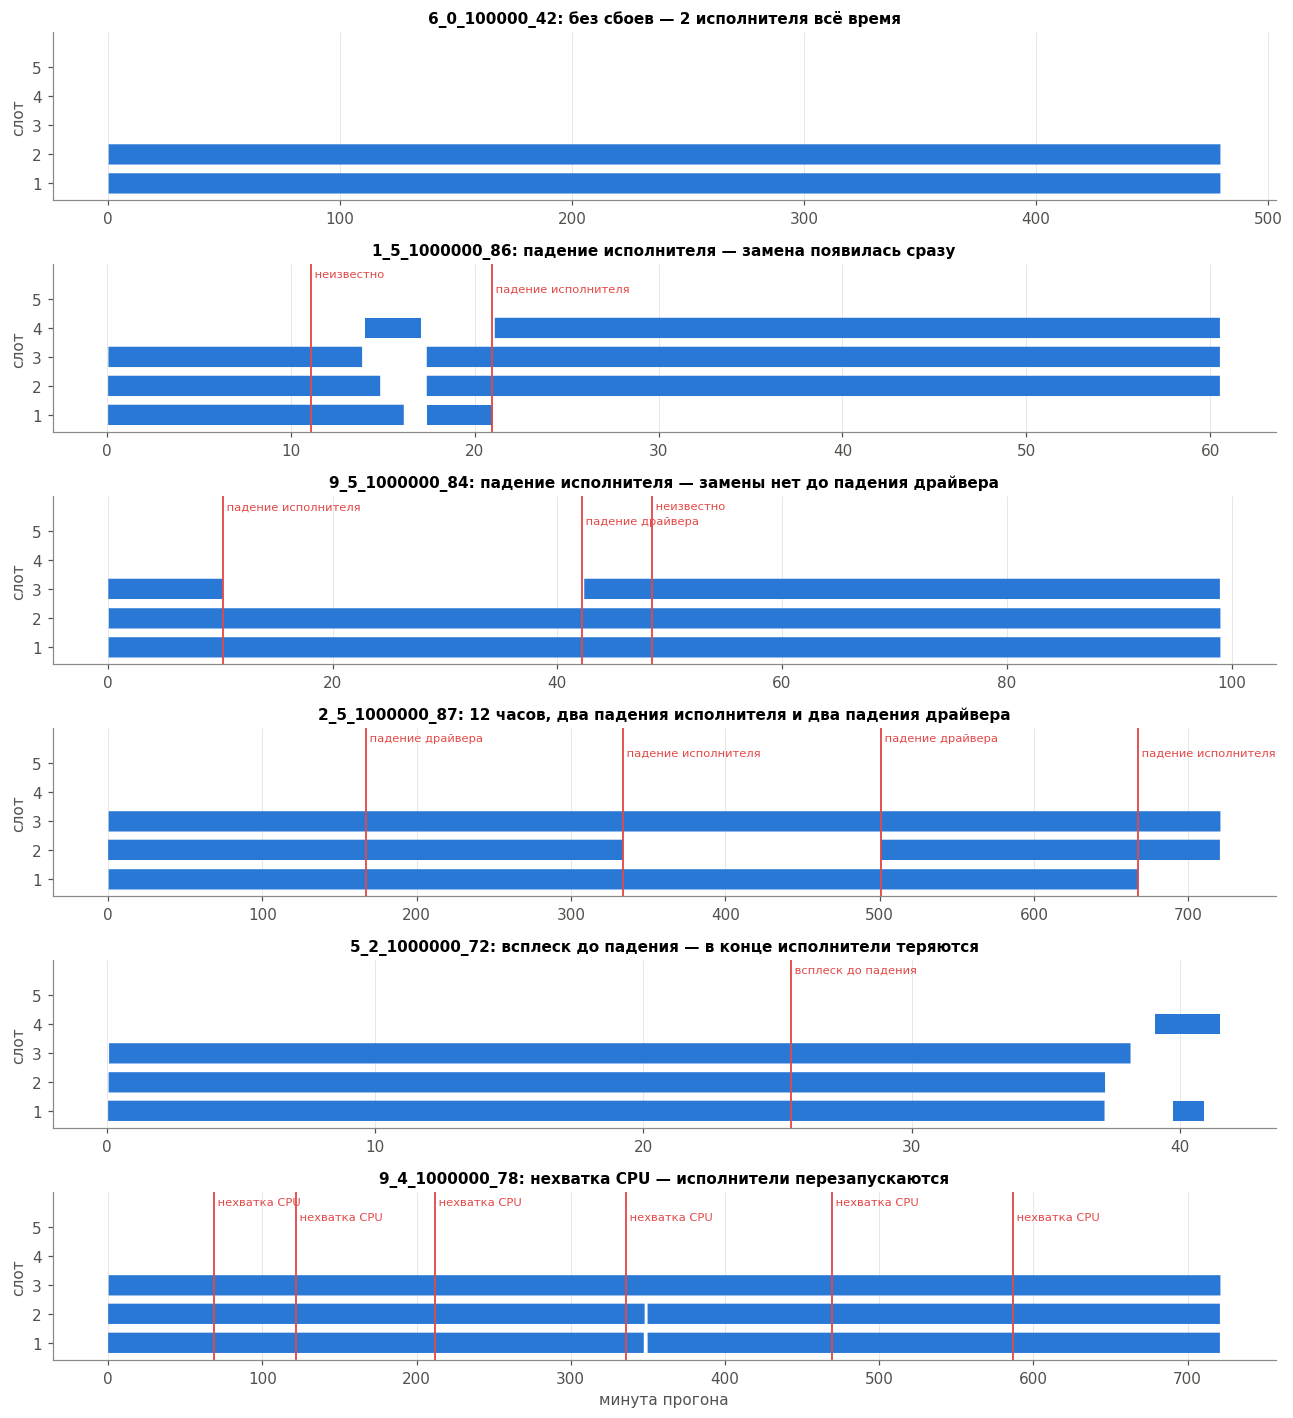

In [24]:
def slots_plot(ax, n, title):
    f = F[n]; x = f.sec / 60
    for i in EXEC:
        a = f[f'slot{i}'].values.astype(bool)
        ax.fill_between(x, i - 0.35, i + 0.35, where=a, color=C[0], lw=0, step='mid')
    for j, r in enumerate(gt[gt.trace_name == n].sort_values('root_cause_start').itertuples()):
        s = (r.root_cause_start - f.t.iloc[0]) / 60
        ax.axvline(s, color=ANOM, lw=1.2)
        ax.text(s, 5.75 if j % 2 == 0 else 5.25, ' ' + TNAME.get(r.anomaly_type, 'неизвестно'), color=ANOM, fontsize=7.5, ha='left')
    ax.set_yticks(list(EXEC)); ax.set_ylim(0.4, 6.2); ax.set_ylabel('слот'); ax.set_title(title, fontsize=10); ax.grid(axis='y', visible=False)

fig, axes = plt.subplots(6, 1, figsize=(12, 13))
for ax, (n, tt) in zip(axes, [('6_0_100000_42', '6_0_100000_42: без сбоев — 2 исполнителя всё время'),
                              ('1_5_1000000_86', '1_5_1000000_86: падение исполнителя — замена появилась сразу'),
                              ('9_5_1000000_84', '9_5_1000000_84: падение исполнителя — замены нет до падения драйвера'),
                              ('2_5_1000000_87', '2_5_1000000_87: 12 часов, два падения исполнителя и два падения драйвера'),
                              ('5_2_1000000_72', '5_2_1000000_72: всплеск до падения — в конце исполнители теряются'),
                              ('9_4_1000000_78', '9_4_1000000_78: нехватка CPU — исполнители перезапускаются')]):
    slots_plot(ax, n, tt)
axes[-1].set_xlabel('минута прогона'); plt.tight_layout(); plt.show()

**Как читать:** каждая строка — слот исполнителя (1–5), синий — исполнитель работает, красные линии — события из разметки.

- **6_0_100000_42:** 8 часов без единого изменения — 2 исполнителя.
- **1_5_1000000_86:** после неразмеченного события на 11-й минуте исполнители как то странно сигают, а при падении исполнителя на 21-й минуте слот 1 пропадает и **сразу** появляется слот 4 — замена.
- **9_5_1000000_84:** исполнитель 3 падает на 10-й минуте, и **замены нет 32 минуты** — до падения драйвера, после которого приложение перезапускается целиком.
- **2_5_1000000_87:** 12 часов. Падение драйвера на 167-й минуте не меняет набор исполнителей; на 334-й теряется исполнитель 2 и возвращается только после второго падения драйвера (на 501-й минуте); на 667-й теряется исполнитель 1 — до конца прогона.
- **5_2_1000000_72:** при всплеске до падения исполнители теряются в конце, затем пробуют запуститься новые.
- **9_4_1000000_78:** на ~348-й минуте, во время сильной нехватки CPU, исполнители 1 и 2 перезапускаются.

### 8.3. Помогает ли третий исполнитель

Прямых экспериментов «добавили исполнителя при той же нагрузке» в датасете нет. Можно лишь сравнить батчи одного приложения с 2 и с 3 исполнителями **при одинаковом входе** (в нормальном режиме, из разных прогонов).

In [25]:
Lall = B[B.label.isin(['normal', 'bursty_input'])]
rows = []
for app in range(1, 11):
    g2, g3 = Lall[(Lall.app == app) & (Lall.n_exec == 2)], Lall[(Lall.app == app) & (Lall.n_exec == 3)]
    if len(g3) < 200: continue
    lo, hi = max(g2.rate.quantile(.02), g3.rate.quantile(.02)), min(g2.rate.quantile(.98), g3.rate.quantile(.98))
    for a, b in zip(np.linspace(lo, hi, 4)[:-1], np.linspace(lo, hi, 4)[1:]):
        x2, x3 = g2[(g2.rate >= a) & (g2.rate < b)].rho, g3[(g3.rate >= a) & (g3.rate < b)].rho
        if len(x2) > 30 and len(x3) > 30:
            rows.append({'приложение': app, 'вход, млн соб/с': f'{a/1e6:.2f}–{b/1e6:.2f}', 'ρ при 2 исполнителях': round(x2.median(), 2),
                         'ρ при 3 исполнителях': round(x3.median(), 2), 'изменение, %': round((x3.median() / x2.median() - 1) * 100),
                         'батчей (2 / 3)': f'{len(x2)} / {len(x3)}'})
cmp = pd.DataFrame(rows); cmp

,приложение,"вход, млн соб/с",ρ при 2 исполнителях,ρ при 3 исполнителях,"изменение, %",батчей (2 / 3)
0,1,0.10–0.85,0.16,0.08,-47,4504 / 76
1,1,1.60–2.35,0.57,0.60,5,7186 / 62
2,2,0.93–1.30,0.83,0.65,-22,7679 / 6085
3,3,0.26–0.32,0.25,0.36,42,1397 / 32
4,4,0.12–0.72,0.16,0.18,9,12554 / 9891
5,5,0.96–1.29,0.63,0.58,-9,31 / 128
6,5,1.62–1.95,0.81,0.75,-7,1954 / 6721
7,9,0.48–0.54,0.24,0.38,55,2025 / 167
8,9,0.54–0.59,0.31,0.38,23,7108 / 127
9,10,0.48–0.50,0.23,0.35,53,1882 / 313


**Что видно:** Как то странно. У приложений 2 и 5 с третьим исполнителем ρ ниже на 7–22%, а у приложений 3, 9 и 10 — наоборот, выше на 23–55%.

**Почему так:** все батчи с 3 исполнителями взяты из прогонов **со сбоями** (пусть и из нормальных участков), а с 2 — в основном из прогонов без сбоев. Условия разные: другая длина прогона, другая история памяти, иногда очень мало батчей. Это не эксперимент типо добавили исполнителя и посмотрели, поэтому **честно оценить эффект добавления исполнителя по этим данным нельзя**.

## 9. Выводы


**1. При какой нагрузке система перестаёт успевать?**
- Когда **загрузка ρ = время обработки батча / интервал устойчиво больше 1**. Проверено на всех 93 прогонах: при средней ρ < 0,9 очередь до 10 батчей вырастает в 1–5% случаев, при ρ > 1 — в 82–88%.
- ρ растёт **почти линейно со входом**, поэтому для каждого приложения можно посчитать предел. С 2 исполнителями он от ~0,4 до ~4 млн событий в секунду в зависимости от «тяжести» приложения.
- Зона **ρ 0,9–1** — работа без запаса: очередь ещё не растёт, но любое отклонение её запускает.

**2. CPU и память вместе с потоком и очередью:**
- В нормальном режиме система **сильно недогружена**: узлы на 7–17%, исполнители на 0,1–0,8 ядра. **CPU выглядит как не очень хороший сигнал** для автоскейлинга этой системы: у приложения 2 ρ доходит до 1 при CPU узлов ~9%.
- При всплесках CPU исполнителей растёт в ~6 раз, память — в ~2 раза, сборка мусора — в ~10 раз.
- При **нехватке CPU** вход не меняется, CPU узла упирается в 100%, а доля времени задач на процессоре падает: по этому «почерку» её можно отличить от роста нагрузки.

**3. Какие признаки появляются до роста очереди?**
- **ρ реагирует мгновенно, очередь — с задержкой.** Устойчивая ρ > 0,9 появлялась в среднем за ~5 минут до того, как очередь дорастала до 10 батчей, а при медленной деградации — за 15–20 минут.
- При медленной деградации (прогон 1_2) ещё раньше видны рост CPU узла и памяти.

**4. Разные причины роста очереди → разные реакции:**
- рост нагрузки → добавить исполнителей;
- нехватка CPU на узле → перенести на свободный узел;
- падение исполнителя → поднять замену;
- остановка входа → тревога, не уменьшать мощность;
- кратковременный «застой» → не реагировать.

 его нужно измерять на стенде.
